<img src=https://audiovisuales.icesi.edu.co/assets/custom/images/ICESI_logo_prin_descriptor_RGB_POSITIVO_0924.jpg width=200>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/juanestebancg2806/ml3-time-series-forecasting/blob/main/sesion-02-regresion-tendencia-estacionalidad/ejercicio2_pronostico_ocupados_regresion.ipynb)

# Pronóstico del número de ocupados en las 13 principales ciudades de Colombia con regresión lineal

**Aprendizaje Automático III — Universidad Icesi**

**Integrantes:** Juan Esteban Cardona, Daniel Velasco

Este notebook construye y evalúa modelos de regresión lineal para pronosticar el número mensual de ocupados, en miles de personas, de las 13 principales ciudades de Colombia en los próximos 6 meses. Los modelos representan la serie como una función del tiempo, con distintas formas de modelar su tendencia y su estacionalidad. Los modelos se eligen con una validación que respeta el orden temporal de los datos, se revisan los supuestos de los residuales del modelo elegido y su desempeño se evalúa en una muestra de prueba con los 6 meses más recientes, que no se usa para tomar ninguna decisión de modelado. Finalmente, el modelo se ajusta con toda la serie para pronosticar de julio a diciembre de 2019.

## 1. Carga de paquetes

El notebook se desarrolló con Python 3.13 y las versiones de las librerías que se instalan en la celda siguiente. En un entorno que ya las tenga no hace falta instalarlas; en Google Colab, la celda de instalación se descomenta y se reinicia la sesión antes de continuar.

Después de cargar los paquetes se imprimen las versiones del entorno. A diferencia de los modelos que se estiman con un optimizador numérico, la regresión por mínimos cuadrados tiene una solución cerrada, por lo que los coeficientes y los errores deberían coincidir entre sistemas operativos o procesadores, salvo diferencias en los últimos decimales.

In [1]:
# Instalación de las librerías con las versiones usadas en este notebook.
# Solo es necesaria en Google Colab o en un entorno que no las tenga instaladas:
# quitar el comentario de la línea %pip y, en Colab, reiniciar la sesión después
# de instalar (Entorno de ejecución > Reiniciar sesión) para que se carguen las
# versiones nuevas. Requiere Python 3.12 o superior.

# %pip install pandas==3.1.1 numpy==2.5.4 matplotlib==3.11.2 statsmodels==0.15.0 scikit-learn==1.9.1 scipy==1.18.1 openpyxl==3.1.5

In [2]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from sklearn.model_selection import TimeSeriesSplit   # validación con origen móvil
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error
from statsmodels.tsa.seasonal import seasonal_decompose   # descomposición (solo para describir la serie)
import statsmodels.api as sm   # regresión lineal por MCO
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch   # autocorrelación y efectos ARCH de los residuales
from statsmodels.sandbox.stats.runs import runstest_1samp  # prueba de rachas
from statsmodels.graphics.tsaplots import plot_acf         # ACF de los residuales
from scipy import stats                                    # Jarque-Bera y Shapiro-Wilk
from statsmodels.tsa.exponential_smoothing.ets import ETSModel   # Holt-Winters del ejercicio anterior

In [3]:
# Versiones del entorno de ejecución, para poder reproducir los resultados
import platform
import sys

import matplotlib
import openpyxl
import scipy
import sklearn
import statsmodels

print(f"{'Python':<14}{sys.version.split()[0]}")
print(f"{'Plataforma':<14}{platform.platform()}")
for nombre_libreria, modulo in [
    ("pandas", pd),
    ("numpy", np),
    ("matplotlib", matplotlib),
    ("statsmodels", statsmodels),
    ("scikit-learn", sklearn),
    ("scipy", scipy),
    ("openpyxl", openpyxl),
]:
    print(f"{nombre_libreria:<14}{modulo.__version__}")

Python        3.13.9
Plataforma    macOS-27.0.1-arm64-arm-64bit-Mach-O
pandas        3.1.1
numpy         2.5.4
matplotlib    3.11.2
statsmodels   0.15.0
scikit-learn  1.9.1
scipy         1.18.1
openpyxl      3.1.5


## 2. Carga y exploración de los datos

Los datos provienen del archivo `datosEmpleo.xlsx`, que contiene series mensuales del mercado laboral de las 13 principales ciudades de Colombia. Para este ejercicio se usa la columna `Ocupados`, que corresponde al número de ocupados en miles de personas. Antes de construir los modelos se revisa el periodo cubierto, si hay valores faltantes y la forma de la serie, porque de ella depende cómo se representan la tendencia y la estacionalidad en la regresión.

Observaciones: 222
Periodo: 2001-01 a 2019-06
Valores faltantes: 0
count      222.0
mean      9160.9
std       1295.5
min       6923.6
25%       7971.1
50%       9139.1
75%      10458.5
max      11037.2
Name: Ocupados, dtype: float64


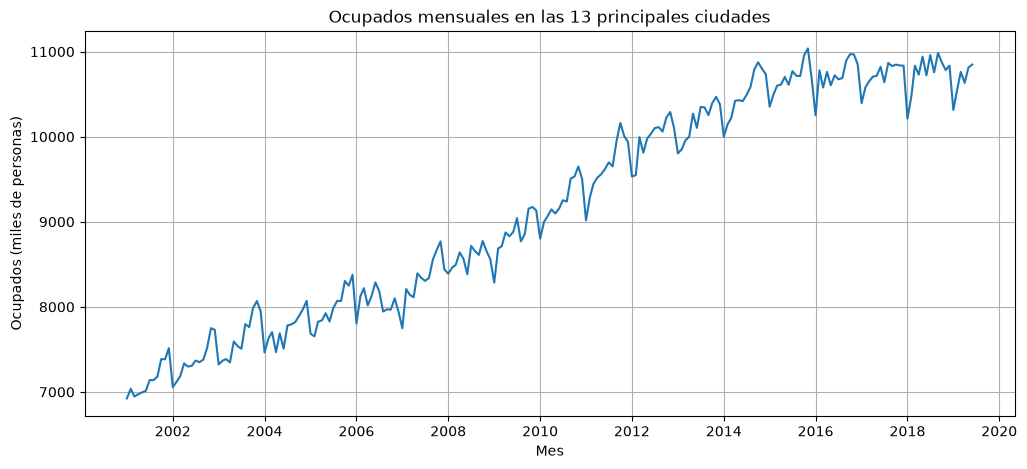

In [4]:
# Carga de datos: la columna "mes" se usa como índice de fechas
data = pd.read_excel(
    "https://raw.githubusercontent.com/dagudelo30/Aprendizaje-automatico-III/main/Clase_1/datosEmpleo.xlsx",
    index_col="mes",
    parse_dates=True,
)

# Serie de ocupados (miles de personas).
# asfreq("MS") declara la frecuencia mensual (inicio de mes): si faltara algún mes,
# aparecería como valor faltante.
ocupados = data["Ocupados"].asfreq("MS")

print("Observaciones:", len(ocupados))
print("Periodo:", ocupados.index.min().strftime("%Y-%m"), "a", ocupados.index.max().strftime("%Y-%m"))
print("Valores faltantes:", ocupados.isna().sum())
print(ocupados.describe().round(1))

# Gráfica de la serie completa
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(ocupados)
ax.set_title("Ocupados mensuales en las 13 principales ciudades")
ax.set_xlabel("Mes")
ax.set_ylabel("Ocupados (miles de personas)")
ax.grid()
plt.show()

### Lectura de la serie

La serie tiene 222 observaciones mensuales, de enero de 2001 a junio de 2019, sin valores faltantes. El número de ocupados va de un mínimo de 6,924 mil personas a un máximo de 11,037 mil, con una media de 9,161 mil.

- **Tendencia:** los ocupados crecen de forma casi lineal entre 2001 y 2015, de cerca de 7 millones a cerca de 10.7 millones, y desde 2016 el crecimiento se detiene y la serie se mantiene entre 10.2 y 11 millones. Esto es importante para la regresión, porque un polinomio del tiempo estima una sola curva para toda la historia: una recta no puede representar el cambio de pendiente, y un polinomio de mayor grado puede seguirlo dentro de la muestra, pero curvarse de forma poco realista al extenderse hacia el futuro.
- **Estacionalidad:** todos los años se repite el mismo patrón. Los ocupados caen con fuerza en enero, se recuperan en los meses siguientes y alcanzan sus valores más altos en el último trimestre. Como el patrón depende solo del mes del año, se puede representar en la regresión con variables que identifiquen el mes.
- **Tamaño de la oscilación:** la caída de enero parece hacerse más profunda a medida que aumenta el nivel de la serie, lo que sugiere un efecto estacional proporcional al nivel y no una cantidad fija de personas.
- **Componente irregular:** además de la tendencia y la estacionalidad, la serie presenta fluctuaciones de un mes a otro sin un patrón claro, que en la regresión corresponden al término de error.

## 3. Partición de entrenamiento y prueba

Como el objetivo es pronosticar los próximos 6 meses, los últimos 6 meses de la serie se reservan como muestra de prueba: de enero a junio de 2019. Así, la evaluación final mide el desempeño de los modelos en el mismo horizonte en el que se usarán. El resto de la serie, de enero de 2001 a diciembre de 2018, forma la muestra de entrenamiento.

La partición respeta el orden temporal: todos los datos de entrenamiento son anteriores a los de prueba. Además, la muestra de prueba no se usa para tomar ninguna decisión de modelado, como el grado de la tendencia o la forma de representar la estacionalidad. Esas decisiones se toman solo con el entrenamiento, para que el error en la prueba sea una estimación honesta del desempeño del modelo con datos que no ha visto.

Entrenamiento: 2001-01 a 2018-12 (216 meses)
Prueba:        2019-01 a 2019-06 (6 meses)


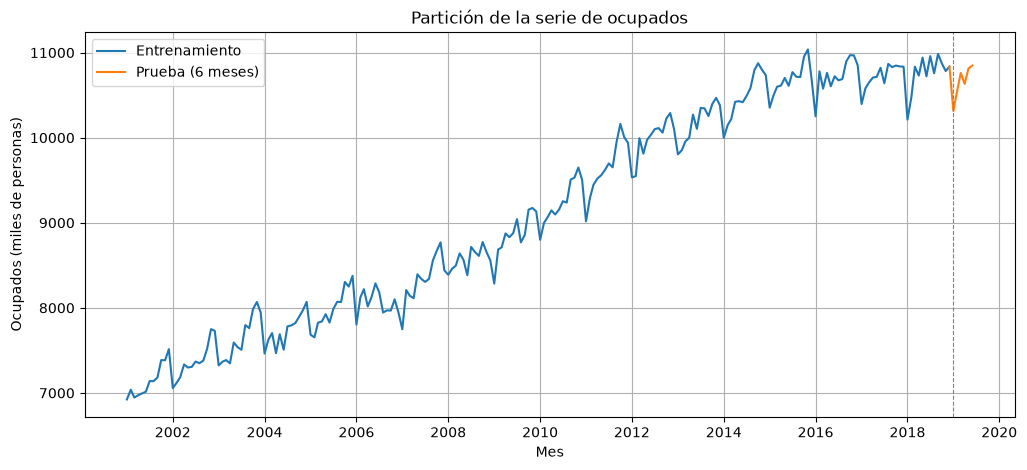

In [5]:
# Horizonte de pronóstico: 6 meses
horizonte = 6

# Partición temporal: los últimos 6 meses se reservan como prueba
train = ocupados.iloc[:-horizonte]
test = ocupados.iloc[-horizonte:]

print("Entrenamiento:", train.index.min().strftime("%Y-%m"), "a", train.index.max().strftime("%Y-%m"), f"({len(train)} meses)")
print("Prueba:       ", test.index.min().strftime("%Y-%m"), "a", test.index.max().strftime("%Y-%m"), f"({len(test)} meses)")

# Gráfica de la partición. La línea de prueba se dibuja desde el último mes de
# entrenamiento solo para que la gráfica se vea continua; los datos no cambian.
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(train, label="Entrenamiento")
ax.plot(pd.concat([train.iloc[-1:], test]), label="Prueba (6 meses)", color="C1")
ax.axvline(test.index[0], color="gray", linestyle="--", linewidth=0.8)
ax.set_title("Partición de la serie de ocupados")
ax.set_xlabel("Mes")
ax.set_ylabel("Ocupados (miles de personas)")
ax.legend()
ax.grid()
plt.show()

La muestra de entrenamiento tiene 216 meses, de enero de 2001 a diciembre de 2018, y la de prueba 6 meses, de enero a junio de 2019. La prueba comienza con la caída estacional de enero y continúa con la recuperación de los meses siguientes, de modo que permite evaluar si los modelos capturan el patrón estacional de la serie y no solo su nivel.

## 4. Componentes de la serie y tipo de estacionalidad

Antes de definir los regresores, la serie de entrenamiento se descompone en tendencia, estacionalidad y residuo. La descomposición no se usa para pronosticar, sino para orientar tres decisiones de la regresión: qué forma debe tener la tendencia, cómo representar el patrón estacional y si el efecto de cada mes es una cantidad fija de personas (estacionalidad aditiva) o un porcentaje del nivel de la serie (estacionalidad multiplicativa).

La última decisión es importante porque una regresión lineal solo suma sus componentes. Si la estacionalidad es multiplicativa, $y_t = T_t \cdot S_t \cdot R_t$, la regresión se ajusta sobre el logaritmo de la serie, donde los componentes se suman: $\log y_t = \log T_t + \log S_t + \log R_t$. Se descompone solo el entrenamiento, para que estas decisiones no dependan de la muestra de prueba.

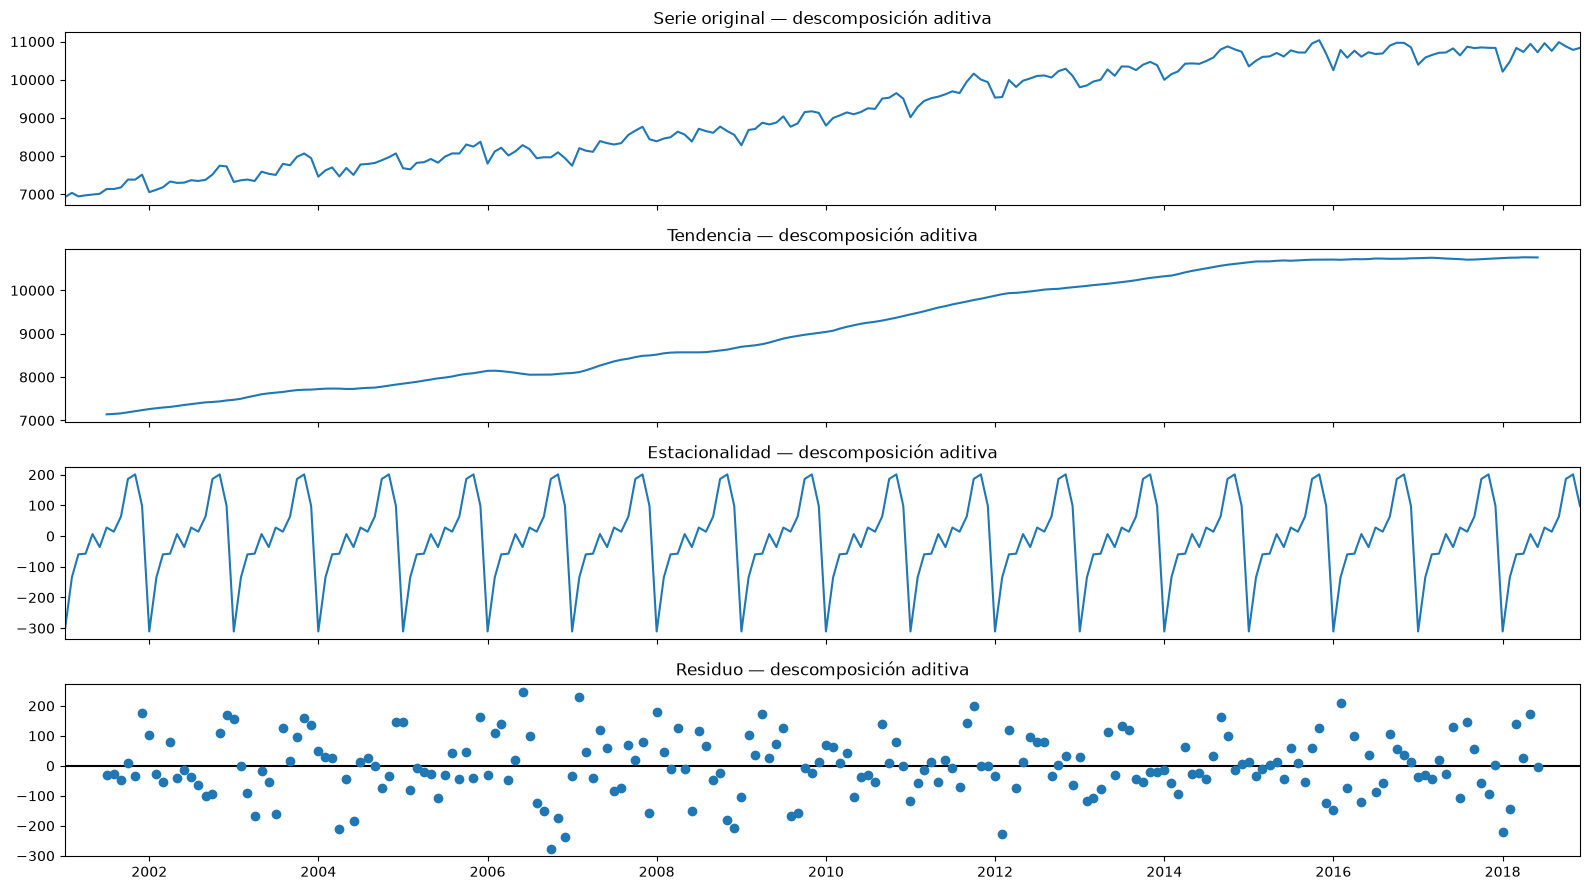

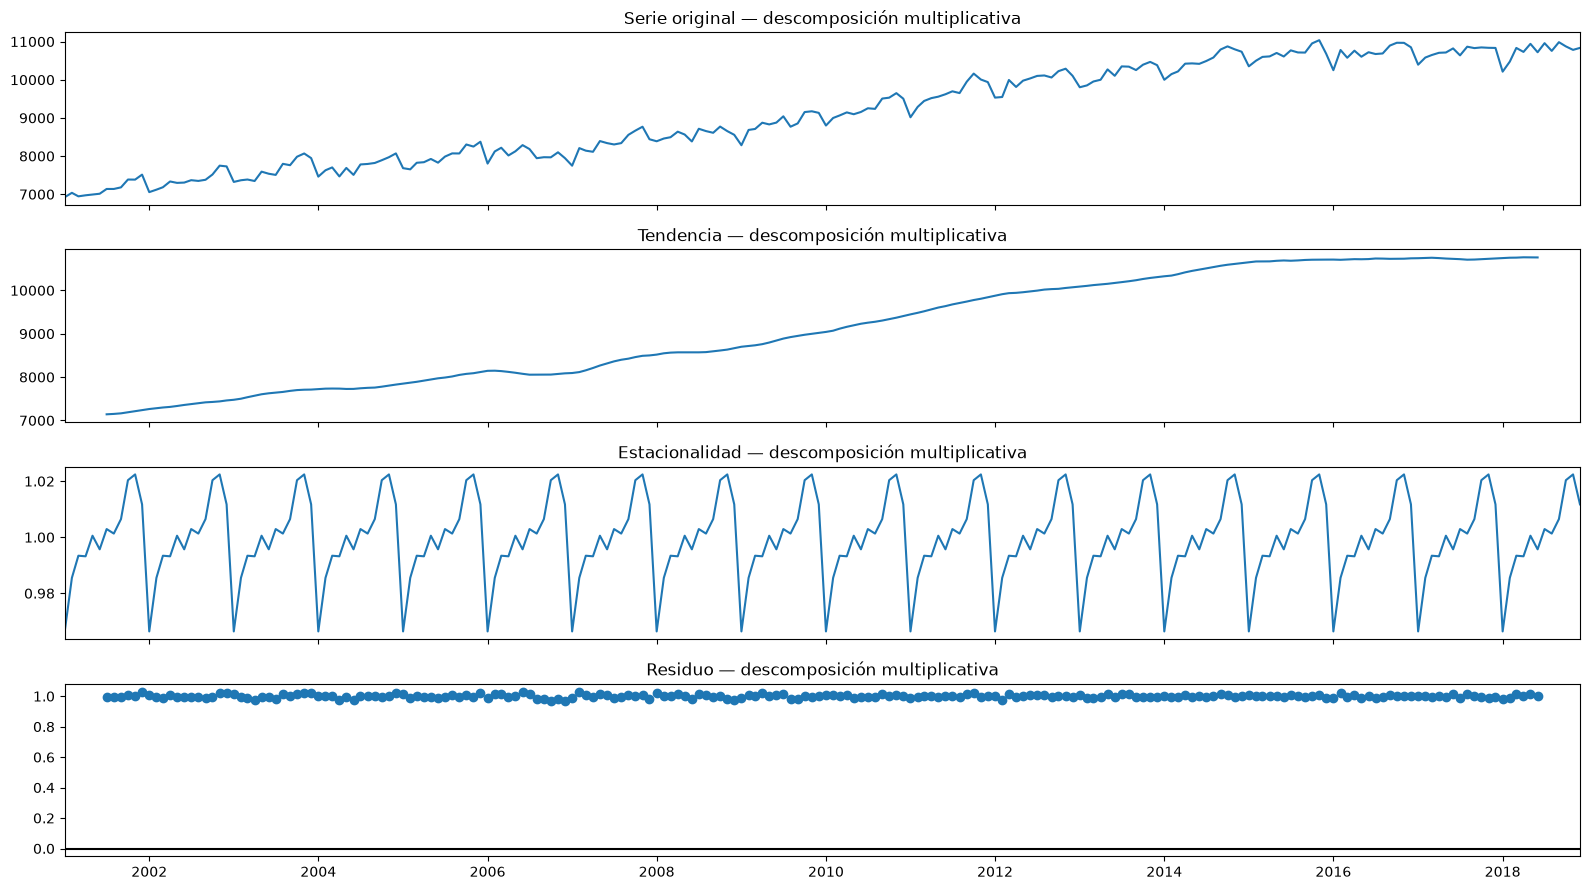

     Aditivo (miles de personas)  Multiplicativo (factor)
Ene                     -310.479                    0.966
Feb                     -134.241                    0.986
Mar                      -59.495                    0.993
Abr                      -57.295                    0.993
May                        6.527                    1.001
Jun                      -35.769                    0.996
Jul                       27.708                    1.003
Ago                       14.336                    1.001
Sep                       63.805                    1.006
Oct                      185.986                    1.020
Nov                      200.802                    1.022
Dic                       98.116                    1.012


In [6]:
# Descomposición clásica del entrenamiento con ambos supuestos
desc_aditiva = seasonal_decompose(train, model="additive")
desc_multiplicativa = seasonal_decompose(train, model="multiplicative")

# Gráficas de ambas descomposiciones, con títulos en español
titulos = ["Serie original", "Tendencia", "Estacionalidad", "Residuo"]
for desc, nombre in [(desc_aditiva, "aditiva"), (desc_multiplicativa, "multiplicativa")]:
    fig = desc.plot()
    fig.set_size_inches((16, 9))
    for eje, titulo in zip(fig.axes, titulos):
        eje.set_title(f"{titulo} — descomposición {nombre}")
        eje.set_ylabel("")
    fig.tight_layout()
    plt.show()

# Efecto estacional estimado para cada mes con ambos supuestos
# (el entrenamiento empieza en enero, así que las primeras 12 filas van de enero a diciembre)
nombres_meses = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
efectos_estacionales = pd.DataFrame({
    "Aditivo (miles de personas)": desc_aditiva.seasonal.iloc[:12].values,
    "Multiplicativo (factor)": desc_multiplicativa.seasonal.iloc[:12].values,
}, index=nombres_meses)
print(efectos_estacionales.round(3))

### Componentes de la serie de entrenamiento

Las dos figuras muestran la descomposición de la serie de entrenamiento con cada supuesto. Cada una tiene cuatro paneles: la serie original, la tendencia, la estacionalidad y el residuo. Bajo el supuesto aditivo, la serie es la suma de las tres piezas (tendencia + estacionalidad + residuo); bajo el multiplicativo, es su producto (tendencia × estacionalidad × residuo).

**Tendencia.** Ambas descomposiciones estiman la misma tendencia, porque las dos la calculan con el mismo promedio móvil centrado de 12 meses. Por esa misma razón, la tendencia no está disponible en los primeros ni en los últimos 6 meses del entrenamiento. Los ocupados crecen de cerca de 7,150 mil a mediados de 2001 a cerca de 10,700 mil en 2015, con una breve pausa entre 2006 y 2007, y desde 2015 se mantienen prácticamente estables hasta 2018. Para la regresión, esto significa que una tendencia lineal estimada con toda la historia tendrá una pendiente positiva que no corresponde a los últimos años, y que un polinomio de mayor grado puede aproximar el aplanamiento, pero también puede extenderlo hacia una caída o una subida que los datos no muestran.

**Estacionalidad.** Ambas descomposiciones encuentran el mismo patrón, repetido de forma idéntica todos los años:

| Mes | Efecto aditivo (miles de personas) | Efecto multiplicativo |
|---|---|---|
| Enero | -310 | 0.966 (3.4 % por debajo de la tendencia) |
| Febrero | -134 | 0.986 (1.4 % por debajo) |
| Octubre | +186 | 1.020 (2.0 % por encima) |
| Noviembre | +201 | 1.022 (2.2 % por encima) |
| Diciembre | +98 | 1.012 (1.2 % por encima) |

Los ocupados caen con fuerza en enero, se recuperan gradualmente entre febrero y abril, se mantienen cerca de la tendencia a mitad de año y alcanzan sus valores más altos en octubre y noviembre. El patrón no es una onda suave: entre diciembre y enero el efecto pasa de +98 a -310 mil personas, un cambio de 408 mil en un solo mes, mientras que entre mayo y septiembre los efectos varían poco. Esta forma es relevante para elegir cómo representar la estacionalidad en la regresión, porque un cambio tan brusco requiere un regresor que permita a cada mes tener su propio efecto, o una combinación de varias ondas de distinta frecuencia.

En el supuesto aditivo, el efecto es una cantidad fija de personas que se suma a la tendencia. En el multiplicativo, es un factor que multiplica la tendencia, por lo que el efecto en personas crece con el nivel de la serie. Por ejemplo, la caída de enero sería de 310 mil personas en cualquier año con el supuesto aditivo, mientras que con el multiplicativo sería de cerca de 245 mil cuando la tendencia está en 7,200 mil y de cerca de 364 mil cuando está en 10,700 mil.

**Residuo.** En la descomposición aditiva, el residuo oscila alrededor de 0, casi siempre entre -250 y 250 mil personas, sin una forma que se repita a simple vista, aunque con algunos valores más alejados entre 2006 y 2007, que coinciden con la pausa de la tendencia. En la descomposición multiplicativa, el residuo no puede evaluarse en la gráfica: la función dibuja la línea de referencia en 0, aunque este residuo gira alrededor de 1, así que los valores quedan comprimidos en una franja casi plana. Además, un patrón que afecte solo a un mes puede quedar escondido entre los demás. Por eso, en la siguiente celda se comparan los residuos de enero, el mes con el mayor efecto estacional, con ambos supuestos y en las mismas unidades.

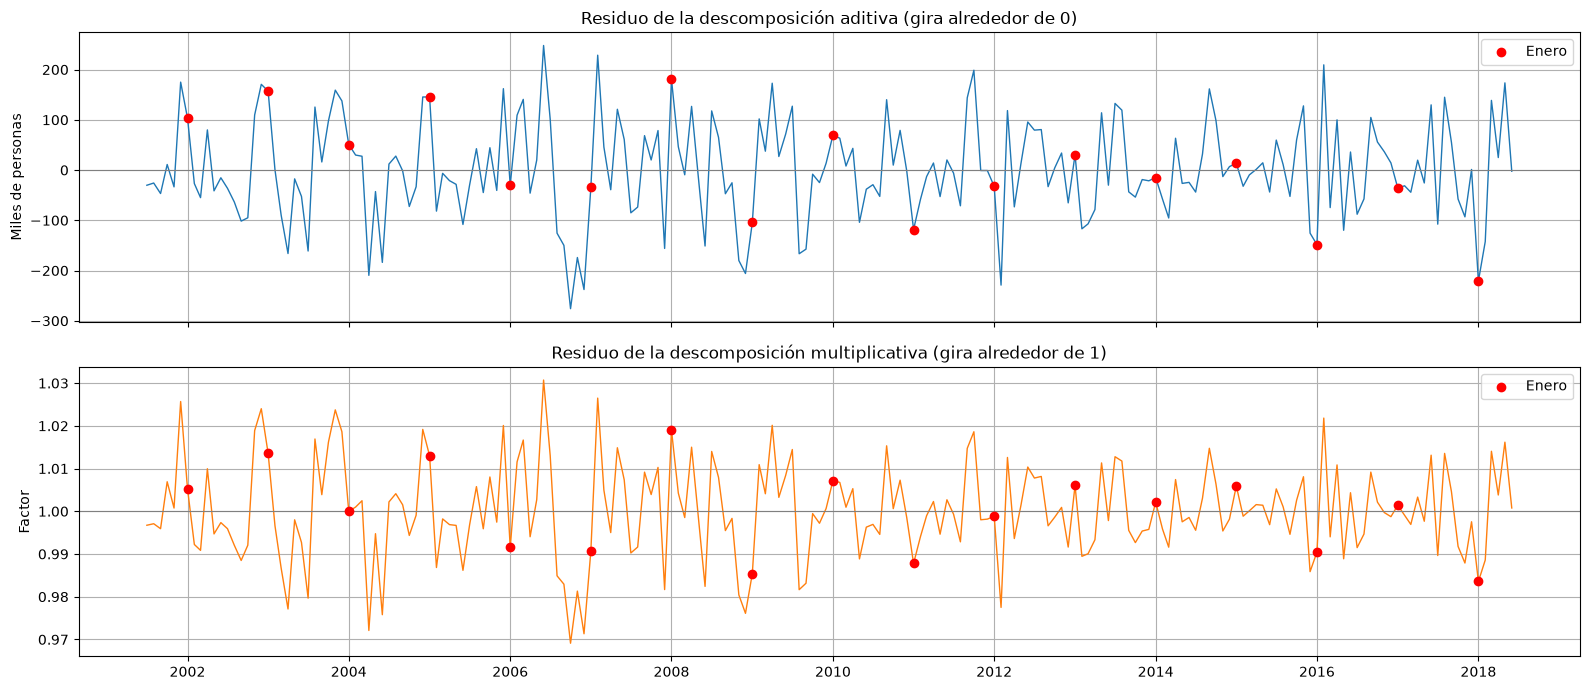

            Tendencia  Residuo aditivo  Residuo multiplicativo  Caída real (miles)  Caída real (%)  Residuo multiplicativo (miles)
mes                                                                                                                               
2002-01-01   7263.377          103.436                   1.005             207.043           2.851                          36.974
2003-01-01   7476.767          157.169                   1.014             153.310           2.050                          97.876
2004-01-01   7722.007           50.852                   1.000             259.627           3.362                          -0.202
2005-01-01   7849.145          145.386                   1.013             165.093           2.103                          98.603
2006-01-01   8144.433          -29.839                   0.992             340.318           4.179                         -66.702
2007-01-01   8093.627          -34.342                   0.991             344.821 

In [7]:
# Comparación de los residuos de enero, el mes con el mayor efecto estacional.
# Si el supuesto es correcto, estos residuos no deben quedar sistemáticamente
# arriba o abajo de la referencia en algún periodo.
es_enero = train.index.month == 1

# Gráfica de ambos residuos en su propia escala, con los eneros resaltados
fig, axes = plt.subplots(2, 1, figsize=(16, 7), sharex=True)

axes[0].plot(desc_aditiva.resid, color="C0", linewidth=1)
axes[0].scatter(train.index[es_enero], desc_aditiva.resid[es_enero], color="red", zorder=3, label="Enero")
axes[0].axhline(0, color="gray", linewidth=0.8)
axes[0].set_title("Residuo de la descomposición aditiva (gira alrededor de 0)")
axes[0].set_ylabel("Miles de personas")
axes[0].legend()
axes[0].grid()

axes[1].plot(desc_multiplicativa.resid, color="C1", linewidth=1)
axes[1].scatter(train.index[es_enero], desc_multiplicativa.resid[es_enero], color="red", zorder=3, label="Enero")
axes[1].axhline(1, color="gray", linewidth=0.8)
axes[1].set_title("Residuo de la descomposición multiplicativa (gira alrededor de 1)")
axes[1].set_ylabel("Factor")
axes[1].legend()
axes[1].grid()

fig.tight_layout()
plt.show()

# Tendencia, residuos y caída real de cada enero.
# La caída real es cuánto quedó enero por debajo de la tendencia en ese año.
eneros = pd.DataFrame({
    "Tendencia": desc_aditiva.trend[es_enero],
    "Residuo aditivo": desc_aditiva.resid[es_enero],
    "Residuo multiplicativo": desc_multiplicativa.resid[es_enero],
})
eneros["Caída real (miles)"] = eneros["Tendencia"] - train[es_enero]
eneros["Caída real (%)"] = 100 * eneros["Caída real (miles)"] / eneros["Tendencia"]

# Residuo multiplicativo expresado en miles para compararlo con el aditivo.
# En el modelo multiplicativo Y = T * S * R, el desvío en miles es T * S * (R - 1).
factor_enero = desc_multiplicativa.seasonal[es_enero]
eneros["Residuo multiplicativo (miles)"] = (
    eneros["Tendencia"] * factor_enero * (eneros["Residuo multiplicativo"] - 1)
)

# Enero de 2001 no tiene tendencia (el promedio móvil centrado pierde los primeros 6 meses)
eneros = eneros.dropna()
print(eneros.round(3).to_string())

comparacion_residuos = eneros[["Residuo aditivo", "Residuo multiplicativo (miles)"]]
print("\nPromedio del valor absoluto del residuo de enero (miles):")
print(comparacion_residuos.abs().mean().round(1).to_string())

print("\nPromedio del residuo de enero por periodo (miles):")
print(pd.DataFrame({
    "2002-2005": comparacion_residuos.loc["2002":"2005"].mean(),
    "2016-2018": comparacion_residuos.loc["2016":"2018"].mean(),
}).round(1).to_string())

### Elección del tipo de estacionalidad

Para decidir entre el supuesto aditivo y el multiplicativo se analizaron los eneros, porque enero es el mes con el mayor efecto estacional: la descomposición aditiva estima una caída fija de 310.5 mil personas frente a la tendencia, y la multiplicativa una caída de 3.4 % (factor de 0.966). Si el supuesto es correcto, los residuos de enero deberían oscilar alrededor de cero sin un patrón en el tiempo. Como los dos residuos están en unidades distintas, el multiplicativo se expresó en miles como $T_t \cdot S_t \cdot (R_t - 1)$, es decir, el valor esperado por el modelo multiplicado por el porcentaje en que se aleja de él.

| Residuo de enero (miles) | Aditivo | Multiplicativo |
|---|---|---|
| Promedio del valor absoluto, 2002-2018 | 87.7 | 74.3 |
| Promedio 2002-2005 | +114.2 | +58.3 |
| Promedio 2016-2018 | -135.0 | -85.0 |

Con el supuesto aditivo hay un sesgo claro. Entre 2002 y 2005, cuando la tendencia estaba entre 7,263 y 7,849 mil, la caída real de enero fue de 153 a 260 mil personas, menor que la estimada, y el residuo queda positivo. En 2016 y 2018, con una tendencia cercana a 10,700 mil, la caída real fue de 459 y 532 mil, mayor que la estimada, y el residuo queda negativo. Es decir, la caída de enero creció con el nivel de la serie, lo que contradice el supuesto aditivo de un efecto fijo en personas. El supuesto multiplicativo reduce este sesgo: el error promedio baja de 87.7 a 74.3 mil (cerca de 15 %) y los promedios por periodo se reducen a +58.3 y -85.0 mil.

El sesgo, sin embargo, no desaparece. La caída de enero como porcentaje de la tendencia varía bastante de un año a otro, entre 1.5 % y 4.9 %, pero en promedio pasó de 2.6 % en 2002-2005 a 4.2 % en 2016-2018, es decir, creció incluso más que en proporción al nivel. Esto sugiere que el patrón estacional cambió con el tiempo. Una regresión con efectos de mes fijos estima un único patrón para todo el periodo de ajuste, igual que la descomposición clásica, de modo que tampoco puede capturar este cambio si se estima con toda la historia.

Por lo tanto, el supuesto multiplicativo describe mejor la serie, pero la ventaja es moderada. En la regresión se evaluarán ambos tipos de estacionalidad: el aditivo ajustando la serie en su escala original y el multiplicativo ajustando su logaritmo. La elección final se hará con el error de pronóstico en la validación.

## 5. Esquema de validación y modelos de referencia

Para elegir entre modelos y configuraciones sin usar la muestra de prueba, se aplica una validación con origen móvil dentro del entrenamiento. Es la versión de la validación cruzada para series de tiempo: en lugar de partir los datos al azar, se definen varios cortes en el tiempo, y en cada uno el modelo se ajusta con los meses anteriores al corte y pronostica los 6 meses siguientes. En la regresión, ajustar significa volver a estimar los coeficientes solo con los datos disponibles hasta el corte, de modo que ningún pronóstico usa información posterior. Se usan 6 cortes, de modo que cada modelo se evalúa en 6 semestres distintos entre 2016 y 2018, y no depende de un solo periodo. En cada corte se calculan dos métricas:

- **RMSE** (raíz del error cuadrático medio), en miles de personas, que penaliza más los errores grandes.
- **MAPE** (error porcentual absoluto medio), en porcentaje del valor real, que permite leer el error en términos relativos.

El criterio principal de selección es el RMSE promedio de los 6 cortes, porque está en las mismas unidades de la serie y castiga con más fuerza los meses en que el pronóstico se aleja mucho del valor real. El MAPE promedio se usa como complemento, y entre los mejores modelos se revisa además en cuántos cortes cada uno supera al naive estacional, para que la elección no dependa de un solo semestre.

Las medidas de ajuste que reporta la regresión, como el $R^2$, no se usan para elegir el modelo, porque se calculan con los mismos datos con los que se estiman los coeficientes. El $R^2$ aumenta siempre que se agrega un regresor, por ejemplo una potencia más alta del tiempo, aunque el modelo pronostique peor fuera de la muestra. Por eso se reportan solo para interpretar el ajuste.

Como referencia se usan dos pronósticos ingenuos. El **naive** repite el último valor observado en los 6 meses, y el **naive estacional** repite el valor del mismo mes del año anterior. Un modelo solo aporta valor si mejora estas referencias.

In [8]:
# Validación con origen móvil dentro del entrenamiento (la muestra de prueba no se usa aquí).
# TimeSeriesSplit no mezcla los datos: cada corte ajusta con los meses anteriores
# y valida con los 6 meses siguientes. Por defecto la ventana de ajuste es expansiva
# (max_train_size=None), es decir, cada corte tiene disponible toda la historia hasta ese punto.
n_cortes = 6
tscv = TimeSeriesSplit(n_splits=n_cortes, test_size=horizonte)

for numero, (idx_ajuste, idx_validacion) in enumerate(tscv.split(train), start=1):
    print(
        f"Corte {numero}: ajuste {train.index[idx_ajuste[0]]:%Y-%m} a {train.index[idx_ajuste[-1]]:%Y-%m} "
        f"({len(idx_ajuste)} meses) | validación {train.index[idx_validacion[0]]:%Y-%m} "
        f"a {train.index[idx_validacion[-1]]:%Y-%m}"
    )

Corte 1: ajuste 2001-01 a 2015-12 (180 meses) | validación 2016-01 a 2016-06
Corte 2: ajuste 2001-01 a 2016-06 (186 meses) | validación 2016-07 a 2016-12
Corte 3: ajuste 2001-01 a 2016-12 (192 meses) | validación 2017-01 a 2017-06
Corte 4: ajuste 2001-01 a 2017-06 (198 meses) | validación 2017-07 a 2017-12
Corte 5: ajuste 2001-01 a 2017-12 (204 meses) | validación 2018-01 a 2018-06
Corte 6: ajuste 2001-01 a 2018-06 (210 meses) | validación 2018-07 a 2018-12


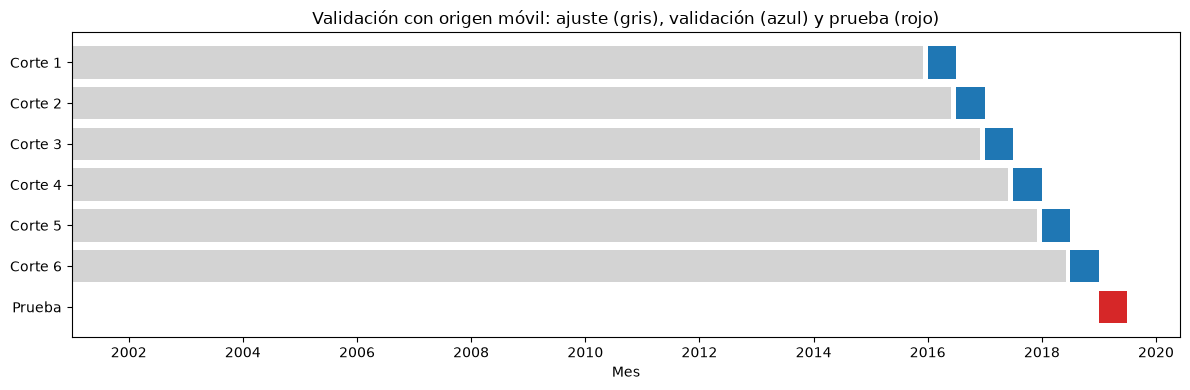

In [9]:
# Diagrama de los cortes de validación y de la muestra de prueba
fig, ax = plt.subplots(figsize=(12, 4))

for numero, (idx_ajuste, idx_validacion) in enumerate(tscv.split(train), start=1):
    inicio_ajuste, fin_ajuste = train.index[idx_ajuste[0]], train.index[idx_ajuste[-1]]
    inicio_validacion, fin_validacion = train.index[idx_validacion[0]], train.index[idx_validacion[-1]]
    # Barra gris: meses de ajuste; barra azul: meses de validación
    ax.barh(numero, fin_ajuste - inicio_ajuste, left=inicio_ajuste, color="lightgray")
    ax.barh(numero, fin_validacion - inicio_validacion + pd.Timedelta(days=30),
            left=inicio_validacion, color="C0")

# Muestra de prueba, reservada hasta el final
ax.barh(n_cortes + 1, test.index[-1] - test.index[0] + pd.Timedelta(days=30),
        left=test.index[0], color="C3")

ax.set_yticks(range(1, n_cortes + 2))
ax.set_yticklabels([f"Corte {numero}" for numero in range(1, n_cortes + 1)] + ["Prueba"])
ax.invert_yaxis()
ax.set_title("Validación con origen móvil: ajuste (gris), validación (azul) y prueba (rojo)")
ax.set_xlabel("Mes")
plt.tight_layout()
plt.show()

El diagrama muestra los 6 cortes de la validación. En cada uno, los datos disponibles para ajustar el modelo van desde enero de 2001 hasta el mes anterior al corte (gris), y el modelo se evalúa en los 6 meses siguientes (azul), de modo que los cortes cubren de forma consecutiva los semestres de 2016 a 2018. La muestra de prueba (rojo) queda por fuera de todos los cortes y solo se usa al final, para evaluar el modelo elegido.

In [10]:
def evaluar_validacion(funcion_pronostico, serie=train, cv=tscv):
    """Evalúa un método de pronóstico en cada corte de la validación con origen móvil.

    funcion_pronostico(serie_ajuste, h) debe devolver h pronósticos usando solo serie_ajuste.
    Devuelve una tabla con el RMSE (miles) y el MAPE (%) de cada corte.
    """
    filas = []
    for idx_ajuste, idx_validacion in cv.split(serie):
        serie_ajuste = serie.iloc[idx_ajuste]
        serie_validacion = serie.iloc[idx_validacion]
        pronostico = funcion_pronostico(serie_ajuste, len(serie_validacion))
        filas.append({
            "inicio_validacion": serie_validacion.index[0].strftime("%Y-%m"),
            "rmse": np.sqrt(mean_squared_error(serie_validacion, pronostico)),
            # sklearn devuelve el MAPE como fracción, por eso se multiplica por 100
            "mape": 100 * mean_absolute_percentage_error(serie_validacion, pronostico),
        })
    return pd.DataFrame(filas).set_index("inicio_validacion")


def pronostico_naive(serie_ajuste, h):
    """Repite el último valor observado en los h meses siguientes."""
    return np.repeat(serie_ajuste.iloc[-1], h)


def pronostico_naive_estacional(serie_ajuste, h, m=12):
    """Repite el valor del mismo mes del año anterior (válido para h <= m)."""
    return serie_ajuste.iloc[-m:].iloc[:h].values


# Resultados por corte de cada método; se irán agregando los modelos de regresión a este diccionario
validacion = {}
validacion["Naive"] = evaluar_validacion(pronostico_naive)
validacion["Naive estacional"] = evaluar_validacion(pronostico_naive_estacional)

for nombre, tabla in validacion.items():
    print(f"\n{nombre}")
    print(tabla.round(2))

resumen_validacion = pd.DataFrame({nombre: tabla.mean() for nombre, tabla in validacion.items()}).T
resumen_validacion.columns = ["RMSE promedio", "MAPE promedio (%)"]
print("\nResumen")
print(resumen_validacion.round(2))


Naive
                     rmse  mape
inicio_validacion              
2016-01            191.58  1.33
2016-07            169.33  1.34
2017-01            245.52  1.95
2017-07             77.88  0.45
2018-01            302.74  2.09
2018-07            167.46  1.33

Naive estacional
                     rmse  mape
inicio_validacion              
2016-01            149.37  1.19
2016-07            113.50  0.86
2017-01            122.75  1.07
2017-07            107.29  0.84
2018-01            153.32  1.29
2018-07            153.90  1.02

Resumen
                  RMSE promedio  MAPE promedio (%)
Naive                    192.42               1.41
Naive estacional         133.36               1.05


### Resultados de los modelos de referencia

Los 6 cortes validan semestres consecutivos entre enero de 2016 y diciembre de 2018, con un ajuste que va de 180 a 210 meses, y ninguno usa la muestra de prueba.

| Modelo | RMSE promedio (miles) | MAPE promedio (%) |
|---|---|---|
| Naive | 192.42 | 1.41 |
| Naive estacional | 133.36 | 1.05 |

El naive estacional tiene un RMSE promedio cerca de 31 % menor que el naive. Como entre 2016 y 2018 el nivel de la serie se mantuvo casi constante, la diferencia entre ambos se debe principalmente a que el naive estacional reproduce el patrón del calendario. El naive tiene sus mayores errores en los cortes que empiezan en enero (245.5 mil en 2017 y 302.7 mil en 2018), porque repite en todo el semestre el valor de diciembre, uno de los más altos del año, justo antes de la caída de enero. El error del naive estacional es más estable entre cortes, de 107.3 a 153.9 mil.

El naive estacional se toma como la referencia a superar: un modelo de regresión solo se considera útil si obtiene un RMSE promedio menor a 133.36 mil y un MAPE promedio menor a 1.05 %. Hay que tener en cuenta que esta referencia no incluye tendencia y que en el periodo de validación la tendencia de la serie fue casi plana, lo que la favorece.

## 6. Regresión con tendencia

Un modelo de regresión para series de tiempo explica cada valor de la serie con regresores que dependen solo de la fecha. El más simple usa un polinomio del tiempo como tendencia:

$$y_t = \beta_0 + \beta_1 t + \beta_2 t^2 + \beta_3 t^3 + \varepsilon_t$$

donde $t$ es el tiempo en años desde enero de 2001 ($t = 0$ en enero de 2001, $t = 1/12$ en febrero, y así sucesivamente). Medir el tiempo en años hace que los coeficientes se lean por año y evita que $t^2$ y $t^3$ tomen valores muy grandes. Los coeficientes se estiman por mínimos cuadrados ordinarios (MCO) con los meses de ajuste de cada corte, y el pronóstico se obtiene evaluando la curva estimada en los 6 meses siguientes.

Se evalúan cuatro tendencias: ninguna (solo la constante, es decir, el promedio del periodo de ajuste), lineal, cuadrática y cúbica. En esta sección los modelos todavía no incluyen estacionalidad, para medir primero cuánto aporta la tendencia por sí sola, y en cada corte se usan todos los meses anteriores al corte. Las funciones de esta sección construyen los regresores de forma general, de modo que en las secciones siguientes se reutilizan para agregar la estacionalidad.

Resumen de la validación (ordenado por RMSE)
                  RMSE promedio  MAPE promedio (%)
Naive estacional         133.36               1.05
Naive                    192.42               1.41
Tend. cúbica             262.15               2.15
Tend. lineal             369.80               3.22
Tend. cuadrática         487.08               4.41
Solo constante          1806.82              16.74


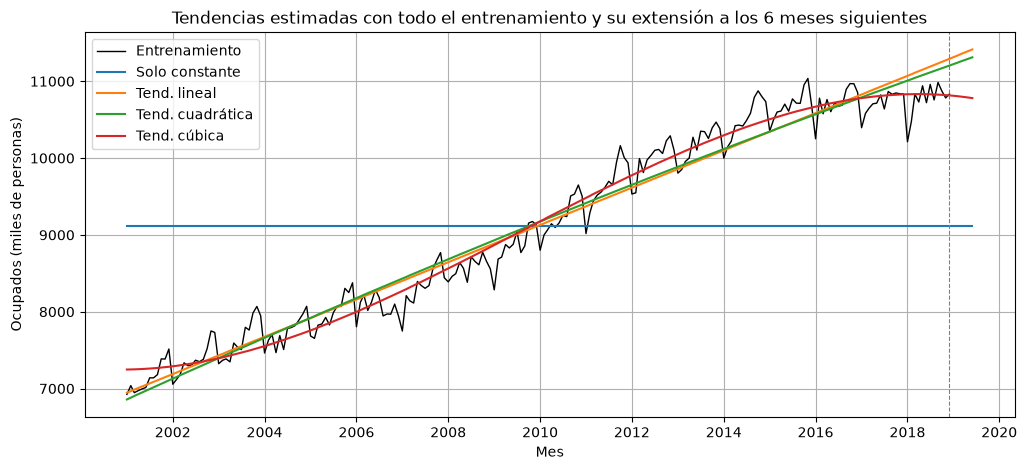


Coeficientes estimados con todo el entrenamiento (t en años):
                     R²     const      t^1     t^2    t^3
Solo constante   -0.000  9119.366      NaN     NaN    NaN
Tend. lineal      0.962  6945.834  242.627     NaN    NaN
Tend. cuadrática  0.963  6858.193  272.114  -1.646    NaN
Tend. cúbica      0.977  7247.538    8.277  35.254 -1.373


In [11]:
# Tiempo de referencia: t = 0 en el primer mes de la serie (enero de 2001)
inicio_serie = ocupados.index[0]


def construir_regresores(fechas, tendencia):
    """Construye la matriz de regresores de la tendencia para las fechas indicadas.

    tendencia: "ninguna", "lineal", "cuadratica" o "cubica" (polinomio en t, medido en años).
    """
    meses_desde_inicio = (fechas.year - inicio_serie.year) * 12 + (fechas.month - inicio_serie.month)
    t = np.asarray(meses_desde_inicio, dtype=float) / 12

    X = pd.DataFrame({"const": np.ones(len(fechas))}, index=fechas)
    grado = {"ninguna": 0, "lineal": 1, "cuadratica": 2, "cubica": 3}[tendencia]
    for potencia in range(1, grado + 1):
        X[f"t^{potencia}"] = t ** potencia
    return X


def fechas_siguientes(serie_ajuste, h):
    """Devuelve las h fechas mensuales posteriores al último mes de serie_ajuste."""
    return pd.date_range(serie_ajuste.index[-1] + pd.DateOffset(months=1), periods=h, freq="MS")


def ajustar_regresion(serie_ajuste, config):
    """Estima por MCO la regresión con la configuración indicada."""
    X = construir_regresores(serie_ajuste.index, config["tendencia"])
    return sm.OLS(serie_ajuste, X).fit()


def pronostico_regresion(serie_ajuste, h, config):
    """Ajusta la regresión con serie_ajuste y pronostica los h meses siguientes."""
    ajuste = ajustar_regresion(serie_ajuste, config)
    X_futuro = construir_regresores(fechas_siguientes(serie_ajuste, h), config["tendencia"])
    return np.asarray(ajuste.predict(X_futuro))


# Configuraciones con tendencia y sin estacionalidad
configuraciones_tendencia = {
    "Solo constante":   dict(tendencia="ninguna"),
    "Tend. lineal":     dict(tendencia="lineal"),
    "Tend. cuadrática": dict(tendencia="cuadratica"),
    "Tend. cúbica":     dict(tendencia="cubica"),
}

for nombre, config in configuraciones_tendencia.items():
    validacion[nombre] = evaluar_validacion(
        lambda serie_ajuste, h, config=config: pronostico_regresion(serie_ajuste, h, config)
    )

resumen_validacion = pd.DataFrame({nombre: tabla.mean() for nombre, tabla in validacion.items()}).T
resumen_validacion.columns = ["RMSE promedio", "MAPE promedio (%)"]
print("Resumen de la validación (ordenado por RMSE)")
print(resumen_validacion.sort_values("RMSE promedio").round(2))

# Coeficientes y R² de cada tendencia estimada con todo el entrenamiento, solo para interpretarlos,
# y gráfica de las curvas estimadas extendidas a los 6 meses siguientes
fechas_grafica = train.index.append(fechas_siguientes(train, horizonte))
coeficientes = {}

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(train, color="black", linewidth=1, label="Entrenamiento")
for nombre, config in configuraciones_tendencia.items():
    ajuste = ajustar_regresion(train, config)
    coeficientes[nombre] = pd.concat([ajuste.params, pd.Series({"R²": ajuste.rsquared})])
    ax.plot(fechas_grafica, ajuste.predict(construir_regresores(fechas_grafica, config["tendencia"])),
            label=nombre)
ax.axvline(train.index[-1], color="gray", linestyle="--", linewidth=0.8)
ax.set_title("Tendencias estimadas con todo el entrenamiento y su extensión a los 6 meses siguientes")
ax.set_xlabel("Mes")
ax.set_ylabel("Ocupados (miles de personas)")
ax.legend(loc="upper left")
ax.grid()
plt.show()

print("\nCoeficientes estimados con todo el entrenamiento (t en años):")
print(pd.DataFrame(coeficientes).T.round(3).to_string())

In [12]:
# Error por corte de las tendencias con regresores de tiempo
modelos_tendencia = ["Tend. lineal", "Tend. cuadrática", "Tend. cúbica"]
print("RMSE por corte (miles):")
print(pd.DataFrame({nombre: validacion[nombre]["rmse"] for nombre in modelos_tendencia}).round(1).to_string())

# Pendiente de cada tendencia en el último mes de ajuste de cada corte (miles de personas por año).
# Es la velocidad de crecimiento que el modelo extiende hacia los 6 meses de validación.
# Se calcula con la derivada del polinomio: b1 + 2*b2*t + 3*b3*t^2.
filas = []
for idx_ajuste, idx_validacion in tscv.split(train):
    serie_ajuste = train.iloc[idx_ajuste]
    t_final = construir_regresores(serie_ajuste.index[-1:], "lineal")["t^1"].iloc[0]
    fila = {"inicio_validacion": train.index[idx_validacion[0]].strftime("%Y-%m")}
    for nombre in modelos_tendencia:
        b = ajustar_regresion(serie_ajuste, configuraciones_tendencia[nombre]).params
        fila[nombre] = b.get("t^1", 0) + 2 * b.get("t^2", 0) * t_final + 3 * b.get("t^3", 0) * t_final ** 2
    filas.append(fila)

pendientes = pd.DataFrame(filas).set_index("inicio_validacion")
print("\nPendiente estimada al final de cada periodo de ajuste (miles de personas por año):")
print(pendientes.round(1).to_string())

RMSE por corte (miles):
                   Tend. lineal  Tend. cuadrática  Tend. cúbica
inicio_validacion                                              
2016-01                   273.9             519.0         443.0
2016-07                   137.9             324.4         165.3
2017-01                   424.8             598.0         383.8
2017-07                   334.8             433.5         131.3
2018-01                   613.4             653.7         345.1
2018-07                   434.0             394.0         104.3

Pendiente estimada al final de cada periodo de ajuste (miles de personas por año):
                   Tend. lineal  Tend. cuadrática  Tend. cúbica
inicio_validacion                                              
2016-01                   263.3             362.2         309.2
2016-07                   260.7             335.2         221.3
2017-01                   259.6             320.2         182.1
2017-07                   255.2             288.4          9

### Resultados de la regresión con tendencia

| Modelo | RMSE promedio (miles) | MAPE promedio (%) | $R^2$ con todo el entrenamiento |
|---|---|---|---|
| Naive estacional | 133.36 | 1.05 | — |
| Naive | 192.42 | 1.41 | — |
| Tendencia cúbica | 262.15 | 2.15 | 0.977 |
| Tendencia lineal | 369.80 | 3.22 | 0.962 |
| Tendencia cuadrática | 487.08 | 4.41 | 0.963 |
| Solo constante | 1806.82 | 16.74 | 0.000 |

Ningún modelo con solo tendencia supera al naive ni al naive estacional. Era de esperar, porque estos modelos no incluyen la estacionalidad, que según la sección 4 mueve la serie entre 310 mil personas por debajo de la tendencia en enero y 201 mil por encima en noviembre. El modelo con solo la constante pronostica el promedio de toda la historia, cerca de 9,100 mil, muy por debajo del nivel de 2016-2018, y tiene un error de más de 1.8 millones de personas.

La comparación entre tendencias muestra que el $R^2$ no ordena los modelos como la validación. La tendencia cuadrática tiene un $R^2$ apenas mayor que la lineal, pero un error de validación cerca de 32 % mayor. La razón aparece al calcular la pendiente de cada tendencia en el último mes de ajuste de cada corte, que es la velocidad de crecimiento que el modelo extiende hacia los meses de validación:

| Inicio del corte | Lineal | Cuadrática | Cúbica |
|---|---|---|---|
| 2016-01 | 263.3 | 362.2 | 309.2 |
| 2016-07 | 260.7 | 335.2 | 221.3 |
| 2017-01 | 259.6 | 320.2 | 182.1 |
| 2017-07 | 255.2 | 288.4 | 96.6 |
| 2018-01 | 251.9 | 265.8 | 49.3 |
| 2018-07 | 246.4 | 233.6 | -22.0 |

*Pendiente en miles de personas por año.*

Con los datos hasta 2015, la tendencia cuadrática se curva hacia arriba: interpreta que el crecimiento se está acelerando y pronostica para 2016 un aumento de 362 mil personas por año, cuando la serie en realidad se estancó. A medida que el ajuste incluye más años sin crecimiento, su pendiente baja, y solo en el último corte queda por debajo de la lineal y obtiene un menor error (394.0 frente a 434.0 mil). La tendencia lineal, en cambio, mantiene una pendiente casi constante de 246 a 263 mil por año en todos los cortes, porque cada año nuevo pesa poco frente a los 15 a 17 años anteriores.

La tendencia cúbica es la única que se adapta al aplanamiento: su pendiente baja de 309.2 a -22.0 mil por año a lo largo de los cortes, y su error baja de 443.0 a 104.3 mil. Sin embargo, la adaptación es lenta, porque el polinomio se estima con toda la historia, y en el último corte la pendiente ya es negativa, mientras que según la descomposición de la sección 4 la tendencia real creció cerca de 17 mil personas por año entre 2016 y 2018. En la gráfica, la curva cúbica empieza a descender al final del entrenamiento, lo que muestra el riesgo de extender un polinomio de grado alto fuera de la muestra.

Estos resultados dejan dos conclusiones para las siguientes secciones. Primero, la tendencia por sí sola no basta y es necesario agregar la estacionalidad. Segundo, un polinomio estimado con toda la historia reacciona tarde al cambio de pendiente de 2016, por lo que más adelante se evalúa estimar los coeficientes solo con los años más recientes.

## 7. Regresión con tendencia y estacionalidad (variables dummy)

La estacionalidad se incorpora con una variable dummy por mes, que vale 1 si la observación corresponde a ese mes y 0 en otro caso:

$$y_t = \beta_0 + f(t) + \sum_{j=2}^{12} \delta_j D_{j,t} + \varepsilon_t$$

donde $f(t)$ es la tendencia polinómica de la sección anterior y $D_{j,t}$ es la dummy del mes $j$. Enero es la categoría base: su efecto queda incluido en la constante $\beta_0$, y cada coeficiente $\delta_j$ mide cuánto difiere el mes $j$ de enero con la misma tendencia. Se usan 11 dummies y no 12 porque, junto con la constante, la doceava sería una combinación lineal exacta de las demás (las 12 siempre suman 1), y MCO no podría estimar los coeficientes.

Con las dummies, cada mes tiene su propio efecto, sin imponer una forma al patrón estacional, lo que permite representar el cambio brusco entre diciembre y enero observado en la sección 4. Se combinan con las cuatro tendencias de la sección anterior y en la escala original de la serie, es decir, con estacionalidad aditiva.

In [13]:
# Se amplía construir_regresores para incluir la estacionalidad. Como el argumento es opcional,
# las configuraciones de la sección anterior siguen construyendo los mismos regresores.
GRADOS_TENDENCIA = {"ninguna": 0, "lineal": 1, "cuadratica": 2, "cubica": 3, "grado_4": 4, "grado_5": 5}


def construir_regresores(fechas, tendencia, estacionalidad="ninguna"):
    """Construye la matriz de regresores para las fechas indicadas.

    tendencia: una de las claves de GRADOS_TENDENCIA (polinomio en t, medido en años).
    estacionalidad: "ninguna" o "dummies" (11 dummies de mes, con enero como categoría base).
    """
    meses_desde_inicio = (fechas.year - inicio_serie.year) * 12 + (fechas.month - inicio_serie.month)
    t = np.asarray(meses_desde_inicio, dtype=float) / 12
    mes = np.asarray(fechas.month)

    X = pd.DataFrame({"const": np.ones(len(fechas))}, index=fechas)
    for potencia in range(1, GRADOS_TENDENCIA[tendencia] + 1):
        X[f"t^{potencia}"] = t ** potencia

    if estacionalidad == "dummies":
        # Las 11 dummies se crean de forma explícita: con pd.get_dummies, un horizonte de
        # 6 meses no tendría todos los meses y las columnas no coincidirían con las del ajuste.
        for numero_mes in range(2, 13):
            X[f"mes_{numero_mes}"] = (mes == numero_mes).astype(float)
    return X


def ajustar_regresion(serie_ajuste, config):
    """Estima por MCO la regresión con la configuración indicada."""
    X = construir_regresores(serie_ajuste.index, config["tendencia"], config.get("estacionalidad", "ninguna"))
    return sm.OLS(serie_ajuste, X).fit()


def pronostico_regresion(serie_ajuste, h, config):
    """Ajusta la regresión con serie_ajuste y pronostica los h meses siguientes."""
    ajuste = ajustar_regresion(serie_ajuste, config)
    X_futuro = construir_regresores(fechas_siguientes(serie_ajuste, h), config["tendencia"],
                                    config.get("estacionalidad", "ninguna"))
    return np.asarray(ajuste.predict(X_futuro))


# Configuraciones con tendencia y estacionalidad con dummies
configuraciones_dummies = {
    "Solo dummies":                dict(tendencia="ninguna",    estacionalidad="dummies"),
    "Tend. lineal + dummies":      dict(tendencia="lineal",     estacionalidad="dummies"),
    "Tend. cuadrática + dummies":  dict(tendencia="cuadratica", estacionalidad="dummies"),
    "Tend. cúbica + dummies":      dict(tendencia="cubica",     estacionalidad="dummies"),
}

for nombre, config in configuraciones_dummies.items():
    validacion[nombre] = evaluar_validacion(
        lambda serie_ajuste, h, config=config: pronostico_regresion(serie_ajuste, h, config)
    )

resumen_validacion = pd.DataFrame({nombre: tabla.mean() for nombre, tabla in validacion.items()}).T
resumen_validacion.columns = ["RMSE promedio", "MAPE promedio (%)"]
print("Resumen de la validación (ordenado por RMSE)")
print(resumen_validacion.sort_values("RMSE promedio").round(2))

# Error por corte frente al naive estacional
comparacion = ["Naive estacional"] + list(configuraciones_dummies)
rmse_por_corte = pd.DataFrame({nombre: validacion[nombre]["rmse"] for nombre in comparacion})
print("\nRMSE por corte (miles):")
print(rmse_por_corte.round(1).to_string())

cortes_mejores = rmse_por_corte.iloc[:, 1:].lt(rmse_por_corte["Naive estacional"], axis=0).sum()
print("\nCortes (de 6) en que cada modelo supera al naive estacional:")
print(cortes_mejores.to_string())

Resumen de la validación (ordenado por RMSE)
                            RMSE promedio  MAPE promedio (%)
Naive estacional                   133.36               1.05
Naive                              192.42               1.41
Tend. cúbica + dummies             222.08               1.91
Tend. cúbica                       262.15               2.15
Tend. lineal + dummies             361.44               3.24
Tend. lineal                       369.80               3.22
Tend. cuadrática                   487.08               4.41
Tend. cuadrática + dummies         491.77               4.47
Solo constante                    1806.82              16.74
Solo dummies                      1829.96              17.01

RMSE por corte (miles):
                   Naive estacional  Solo dummies  Tend. lineal + dummies  Tend. cuadrática + dummies  Tend. cúbica + dummies
inicio_validacion                                                                                                            
2016-01

### Resultados de la regresión con tendencia y dummies

| Tendencia | RMSE sin dummies (miles) | RMSE con dummies (miles) | MAPE con dummies (%) | Cortes en que supera al naive estacional |
|---|---|---|---|---|
| Cúbica | 262.15 | 222.08 | 1.91 | 1 |
| Lineal | 369.80 | 361.44 | 3.24 | 0 |
| Cuadrática | 487.08 | 491.77 | 4.47 | 0 |
| Ninguna | 1806.82 | 1829.96 | 17.01 | 0 |

Agregar las dummies de mes casi no cambia el error: el RMSE baja cerca de 15 % con la tendencia cúbica y 2 % con la lineal, y sube levemente con la cuadrática. Ningún modelo supera al naive estacional en promedio (133.36 mil), y solo el modelo con tendencia cúbica lo supera en un corte, el de julio de 2018.

La razón es que el error de estos modelos proviene principalmente de la tendencia y no de la estacionalidad. Las dummies corrigen el patrón de los meses, que según la sección 4 mueve la serie entre 310 mil personas por debajo de la tendencia y 201 mil por encima, pero no corrigen el nivel. Con la tendencia lineal, el error por corte crece de 174.7 mil en el primer semestre de 2016 a 543.9 mil en el segundo de 2018, porque el modelo sigue pronosticando un crecimiento de cerca de 250 mil personas por año sobre una serie que se estancó, y la diferencia se acumula. Con la tendencia cúbica ocurre lo contrario: el error baja de 297.3 a 128.5 mil a medida que su pendiente se adapta al aplanamiento, como se vio en la sección anterior.

El modelo con solo dummies empeora frente al que solo tiene la constante. Sin un término de tendencia, cada coeficiente de mes recoge, además del efecto estacional, el crecimiento promedio de la serie entre enero y ese mes. Por ejemplo, como la serie creció cerca de 20 mil personas por mes durante la mayor parte del periodo, el efecto de diciembre frente a enero queda sobreestimado en cerca de 220 mil personas por la sola tendencia.

Por lo tanto, la estacionalidad solo mejora el pronóstico si la tendencia está bien especificada. La tendencia cúbica es la mejor con y sin estacionalidad, y es el grado más alto evaluado hasta ahora. Para verificar que la búsqueda no quedó corta en ese borde, a continuación se evalúan tendencias de grado 4 y 5 con dummies.

In [14]:
# Revisión del borde de la búsqueda: grados 4 y 5 con dummies
configuraciones_grado_alto = {
    "Tend. grado 4 + dummies": dict(tendencia="grado_4", estacionalidad="dummies"),
    "Tend. grado 5 + dummies": dict(tendencia="grado_5", estacionalidad="dummies"),
}

for nombre, config in configuraciones_grado_alto.items():
    validacion[nombre] = evaluar_validacion(
        lambda serie_ajuste, h, config=config: pronostico_regresion(serie_ajuste, h, config)
    )

# Comparación de todos los grados con dummies
modelos_grado = ["Tend. lineal + dummies", "Tend. cuadrática + dummies", "Tend. cúbica + dummies",
                 "Tend. grado 4 + dummies", "Tend. grado 5 + dummies"]
resumen_grados = pd.DataFrame({
    "RMSE promedio": {nombre: validacion[nombre]["rmse"].mean() for nombre in modelos_grado},
    "MAPE promedio (%)": {nombre: validacion[nombre]["mape"].mean() for nombre in modelos_grado},
    "Cortes mejores que naive est.": {
        nombre: int((validacion[nombre]["rmse"] < validacion["Naive estacional"]["rmse"]).sum())
        for nombre in modelos_grado
    },
})
print("Validación por grado de la tendencia (con dummies):")
print(resumen_grados.round(2).to_string())

print("\nRMSE por corte (miles):")
print(pd.DataFrame({nombre: validacion[nombre]["rmse"] for nombre in modelos_grado}).round(1).to_string())


# Pendiente de la tendencia en el último mes de ajuste de cada corte (derivada del polinomio)
def pendiente_final(ajuste, t_final):
    """Pendiente de la tendencia polinómica en t_final, en miles de personas por año."""
    return sum(k * ajuste.params.get(f"t^{k}", 0) * t_final ** (k - 1) for k in range(1, 6))


filas = []
for idx_ajuste, idx_validacion in tscv.split(train):
    serie_ajuste = train.iloc[idx_ajuste]
    t_final = construir_regresores(serie_ajuste.index[-1:], "lineal")["t^1"].iloc[0]
    fila = {"inicio_validacion": train.index[idx_validacion[0]].strftime("%Y-%m")}
    for nombre in modelos_grado[2:]:
        config = {**configuraciones_dummies, **configuraciones_grado_alto}[nombre]
        fila[nombre] = pendiente_final(ajustar_regresion(serie_ajuste, config), t_final)
    filas.append(fila)

print("\nPendiente estimada al final de cada periodo de ajuste (miles de personas por año):")
print(pd.DataFrame(filas).set_index("inicio_validacion").round(1).to_string())

Validación por grado de la tendencia (con dummies):
                            RMSE promedio  MAPE promedio (%)  Cortes mejores que naive est.
Tend. lineal + dummies             361.44               3.24                              0
Tend. cuadrática + dummies         491.77               4.47                              0
Tend. cúbica + dummies             222.08               1.91                              1
Tend. grado 4 + dummies            193.53               1.58                              1
Tend. grado 5 + dummies            129.50               1.04                              4

RMSE por corte (miles):
                   Tend. lineal + dummies  Tend. cuadrática + dummies  Tend. cúbica + dummies  Tend. grado 4 + dummies  Tend. grado 5 + dummies
inicio_validacion                                                                                                                              
2016-01                             174.7                       410.6              

### Revisión de tendencias de mayor grado

| Tendencia (con dummies) | RMSE promedio (miles) | MAPE promedio (%) | Cortes en que supera al naive estacional |
|---|---|---|---|
| Cúbica | 222.08 | 1.91 | 1 |
| Grado 4 | 193.53 | 1.58 | 1 |
| Grado 5 | 129.50 | 1.04 | 4 |

Cada grado adicional reduce el error, y con grado 5 el modelo obtiene un RMSE promedio menor que el del naive estacional (133.36 mil) y lo supera en 4 de los 6 cortes. Sin embargo, la pendiente estimada al final de cada periodo de ajuste muestra que esta mejora no proviene de representar mejor la tendencia. Desde el segundo corte, las tendencias de grado 4 y 5 tienen pendientes negativas, de hasta -295.2 y -139.0 mil personas por año, es decir, pronostican una caída del número de ocupados, mientras que según la descomposición de la sección 4 la serie creció cerca de 17 mil personas por año entre 2016 y 2018.

Estos modelos reducen el error porque un polinomio de grado alto se curva para seguir de cerca los últimos años del ajuste, de modo que el pronóstico parte de un nivel cercano al de las observaciones más recientes, y en un horizonte de 6 meses una pendiente equivocada acumula poco error: con -139 mil personas por año, la diferencia en medio año es de cerca de 70 mil. La ganancia proviene de aproximar el nivel reciente de la serie, no de modelar su tendencia. Además, la forma en que el polinomio se curva al final de la muestra cambia de un corte a otro: la pendiente de grado 5 pasa de +51.4 a -139.0 mil personas por año, y en los cortes de 2018 los grados 4 y 5 tienen errores mayores que la cúbica (309.5 y 214.7 frente a 189.7 mil en enero de 2018). Como el error sigue bajando con cada grado, aumentar el grado no tiene un punto de parada natural y llevaría a ajustar la curva a las últimas observaciones de cada corte.

El problema de fondo es que una tendencia polinómica estimada con toda la historia da el mismo peso a los años de crecimiento que a los años recientes, y no puede representar el cambio de pendiente de 2016 sin curvarse de forma poco realista. En lugar de seguir aumentando el grado, en la siguiente sección se estima la tendencia solo con los años más recientes, que busca el mismo efecto de seguir el nivel actual de la serie, pero de forma directa y con tendencias de bajo grado. Los modelos de grado 4 y 5 se mantienen en la comparación, teniendo en cuenta que sus pronósticos implican una caída de la serie que los datos no muestran.

## 8. Ventana móvil frente a ventana recursiva

Hasta ahora, en cada corte los coeficientes se estimaron con todos los meses disponibles desde enero de 2001 (ventana recursiva o expansiva). Con una **ventana móvil**, en cambio, se usan solo los últimos $w$ meses antes del corte, de modo que la estimación olvida la historia más antigua. Para esta serie, la ventaja esperada es que la pendiente se estime con los años en que la serie ya se había estancado, en lugar de promediarla con el crecimiento de 2001 a 2015. La desventaja es que con menos datos los coeficientes se estiman con más incertidumbre, en particular los efectos de cada mes, que con una ventana de 24 meses se estiman con solo 2 observaciones por mes.

Se evalúan ventanas de 24, 36, 48, 60 y 96 meses (2, 3, 4, 5 y 8 años) con tendencias de grado bajo (ninguna, lineal y cuadrática) y estacionalidad con dummies. No se usan grados mayores, porque con una ventana corta el polinomio no necesita curvarse para seguir un cambio de pendiente, y un grado alto con pocos datos aumentaría el riesgo de extrapolar de forma inestable. La ventana recursiva de las secciones anteriores sirve como referencia, porque equivale a una ventana que incluye toda la historia.

In [15]:
# Se amplía ajustar_regresion para permitir una ventana móvil: si config["ventana"] es un
# número de meses, solo se usan los últimos meses de serie_ajuste. pronostico_regresion
# usa esta función, por lo que no necesita cambios.
def ajustar_regresion(serie_ajuste, config):
    """Estima por MCO la regresión con la configuración indicada.

    Si config["ventana"] es un número de meses, se usan solo los últimos meses (ventana móvil);
    si no se indica, se usan todos los meses disponibles (ventana recursiva).
    """
    ventana = config.get("ventana")
    if ventana is not None:
        serie_ajuste = serie_ajuste.iloc[-ventana:]
    X = construir_regresores(serie_ajuste.index, config["tendencia"], config.get("estacionalidad", "ninguna"))
    return sm.OLS(serie_ajuste, X).fit()


# Configuraciones con ventana móvil: tendencias de grado bajo con dummies
ventanas = [24, 36, 48, 60, 96]
tendencias_ventana = {"Sin tend.": "ninguna", "Tend. lineal": "lineal", "Tend. cuadrática": "cuadratica"}

configuraciones_ventana = {}
for w in ventanas:
    for etiqueta, tendencia in tendencias_ventana.items():
        configuraciones_ventana[f"{etiqueta} + dummies, ventana {w}"] = dict(
            tendencia=tendencia, estacionalidad="dummies", ventana=w
        )

for nombre, config in configuraciones_ventana.items():
    validacion[nombre] = evaluar_validacion(
        lambda serie_ajuste, h, config=config: pronostico_regresion(serie_ajuste, h, config)
    )

# Tabla de RMSE promedio por tendencia (filas) y ventana (columnas), incluida la ventana recursiva
tabla_rmse = pd.DataFrame(index=list(tendencias_ventana), columns=[*map(str, ventanas), "Recursiva"], dtype=float)
tabla_mape = tabla_rmse.copy()
nombres_recursiva = {"Sin tend.": "Solo dummies", "Tend. lineal": "Tend. lineal + dummies",
                     "Tend. cuadrática": "Tend. cuadrática + dummies"}
for etiqueta in tendencias_ventana:
    for w in ventanas:
        tabla = validacion[f"{etiqueta} + dummies, ventana {w}"]
        tabla_rmse.loc[etiqueta, str(w)] = tabla["rmse"].mean()
        tabla_mape.loc[etiqueta, str(w)] = tabla["mape"].mean()
    tabla_rmse.loc[etiqueta, "Recursiva"] = validacion[nombres_recursiva[etiqueta]]["rmse"].mean()
    tabla_mape.loc[etiqueta, "Recursiva"] = validacion[nombres_recursiva[etiqueta]]["mape"].mean()

print("RMSE promedio de validación (miles), por tendencia y tamaño de ventana (meses):")
print(tabla_rmse.round(2).to_string())
print("\nMAPE promedio de validación (%), por tendencia y tamaño de ventana (meses):")
print(tabla_mape.round(2).to_string())

# Los 5 mejores modelos con ventana móvil, con su error por corte y cortes ganados al naive estacional
resumen_ventana = pd.DataFrame({
    "RMSE promedio": {nombre: validacion[nombre]["rmse"].mean() for nombre in configuraciones_ventana},
    "MAPE promedio (%)": {nombre: validacion[nombre]["mape"].mean() for nombre in configuraciones_ventana},
    "Cortes mejores que naive est.": {
        nombre: int((validacion[nombre]["rmse"] < validacion["Naive estacional"]["rmse"]).sum())
        for nombre in configuraciones_ventana
    },
}).sort_values("RMSE promedio")
print("\nMejores modelos con ventana móvil:")
print(resumen_ventana.head(5).round(2).to_string())

mejores_ventana = ["Naive estacional"] + list(resumen_ventana.index[:5])
print("\nRMSE por corte (miles):")
print(pd.DataFrame({nombre: validacion[nombre]["rmse"] for nombre in mejores_ventana}).round(1).to_string())

RMSE promedio de validación (miles), por tendencia y tamaño de ventana (meses):
                      24      36      48      60      96  Recursiva
Sin tend.         141.78  195.78  270.02  367.71  779.37    1829.96
Tend. lineal      123.68  157.16  196.39  229.49  397.28     361.44
Tend. cuadrática  142.64  137.44  148.14  143.58  142.89     491.77

MAPE promedio de validación (%), por tendencia y tamaño de ventana (meses):
                    24    36    48    60    96  Recursiva
Sin tend.         1.09  1.62  2.28  3.24  7.18      17.01
Tend. lineal      0.94  1.29  1.70  1.98  3.56       3.24
Tend. cuadrática  1.10  1.09  1.13  1.16  1.17       4.47

Mejores modelos con ventana móvil:
                                        RMSE promedio  MAPE promedio (%)  Cortes mejores que naive est.
Tend. lineal + dummies, ventana 24             123.68               0.94                              3
Tend. cuadrática + dummies, ventana 36         137.44               1.09                       

### Resultados de la ventana móvil

RMSE promedio de validación (miles) por tendencia y tamaño de la ventana:

| Tendencia (con dummies) | 24 meses | 36 meses | 48 meses | 60 meses | 96 meses | Recursiva |
|---|---|---|---|---|---|---|
| Sin tendencia | 141.78 | 195.78 | 270.02 | 367.71 | 779.37 | 1829.96 |
| Lineal | **123.68** | 157.16 | 196.39 | 229.49 | 397.28 | 361.44 |
| Cuadrática | 142.64 | 137.44 | 148.14 | 143.58 | 142.89 | 491.77 |

Estimar los coeficientes solo con los años recientes reduce el error de forma importante. Con la tendencia lineal, el RMSE baja de 361.44 mil con la ventana recursiva a 123.68 mil con una ventana de 24 meses, cerca de 66 % menos, porque la pendiente se estima con los dos últimos años, cuando la serie ya se había estancado, y no con el crecimiento de 2001 a 2015. El modelo sin tendencia también mejora al reducir la ventana, porque su constante pasa a ser el nivel promedio de los años recientes y no el de toda la historia. La tendencia cuadrática, en cambio, tiene un error parecido con cualquier ventana, entre 137.44 y 148.14 mil, porque su curvatura le permite seguir el aplanamiento incluso con 8 años de datos, pero ninguna de sus versiones alcanza a la lineal con 24 meses.

| Modelo | RMSE promedio (miles) | MAPE promedio (%) | Cortes en que supera al naive estacional |
|---|---|---|---|
| Tendencia lineal + dummies, ventana de 24 meses | 123.68 | 0.94 | 3 |
| Tendencia cuadrática + dummies, ventana de 36 meses | 137.44 | 1.09 | 2 |
| Sin tendencia + dummies, ventana de 24 meses | 141.78 | 1.09 | 3 |
| Naive estacional | 133.36 | 1.05 | — |

La tendencia lineal con dummies y una ventana de 24 meses es el primer modelo de regresión con una tendencia de grado bajo que supera al naive estacional en las dos métricas: reduce el RMSE promedio en cerca de 7.3 % y el MAPE de 1.05 % a 0.94 %. Supera al naive estacional en 3 de los 6 cortes, con las mayores diferencias en julio de 2016 y enero de 2017 (57.5 y 65.9 mil frente a 113.5 y 122.8 mil). Pierde en enero de 2016, cuando su ventana de ajuste corresponde a 2014 y 2015, años en que la serie todavía crecía, y el modelo extiende ese crecimiento al primer año sin aumento; y en enero de 2018, el corte con la mayor caída de enero del entrenamiento (532 mil personas frente a la tendencia, según la sección 4), que es difícil para todos los modelos.

La mejor ventana es la más corta evaluada. No se evalúan ventanas menores a 24 meses porque, con menos de dos años completos, algunos meses tendrían una sola observación en el ajuste, y su efecto estimado sería exactamente ese valor, sin promediar entre años. Además, con 24 meses el modelo ya estima 13 coeficientes (la constante, la pendiente y 11 dummies) con 24 observaciones. Por eso, en la siguiente sección se evalúa una forma de representar la estacionalidad con menos coeficientes.

## 9. Estacionalidad con términos de Fourier

En lugar de 11 dummies, la estacionalidad se puede representar con $K$ pares de funciones seno y coseno con periodo de 12 meses:

$$s_t = \sum_{k=1}^{K} \left[ a_k \sin\left(\frac{2\pi k\, m_t}{12}\right) + b_k \cos\left(\frac{2\pi k\, m_t}{12}\right) \right]$$

donde $m_t$ es el número del mes (1 a 12). Cada par agrega una onda que se repite $k$ veces por año: con $K = 1$ el patrón estacional es una sola onda suave, y cada término adicional permite representar cambios más bruscos entre meses. Con $K = 6$ se obtienen 11 regresores, porque el seno de frecuencia 6 vale cero en todos los meses, y el modelo es equivalente al de 11 dummies.

La ventaja de los términos de Fourier es que con un $K$ pequeño la estacionalidad se estima con menos coeficientes, lo que reduce la incertidumbre de las estimaciones cuando la ventana tiene pocos datos. La desventaja es que un patrón suave puede no representar bien la caída brusca de enero observada en la sección 4. Para que la comparación con las dummies sea equivalente, se evalúan $K$ de 1 a 6 con las mismas tendencias (sin tendencia, lineal y cuadrática) y las mismas ventanas de la sección anterior (24, 36, 48, 60 y 96 meses, y la ventana recursiva). Como verificación, el modelo con $K = 6$ debe obtener exactamente el mismo error que el modelo con dummies en cada combinación.

In [16]:
# Se amplía construir_regresores para incluir términos de Fourier. ajustar_regresion y
# pronostico_regresion se redefinen para pasar el número de pares K.
def construir_regresores(fechas, tendencia, estacionalidad="ninguna", K=None):
    """Construye la matriz de regresores para las fechas indicadas.

    tendencia: una de las claves de GRADOS_TENDENCIA (polinomio en t, medido en años).
    estacionalidad: "ninguna", "dummies" (11 dummies de mes, con enero como categoría base)
                    o "fourier" (K pares seno-coseno con periodo de 12 meses).
    """
    meses_desde_inicio = (fechas.year - inicio_serie.year) * 12 + (fechas.month - inicio_serie.month)
    t = np.asarray(meses_desde_inicio, dtype=float) / 12
    mes = np.asarray(fechas.month)

    X = pd.DataFrame({"const": np.ones(len(fechas))}, index=fechas)
    for potencia in range(1, GRADOS_TENDENCIA[tendencia] + 1):
        X[f"t^{potencia}"] = t ** potencia

    if estacionalidad == "dummies":
        # Las 11 dummies se crean de forma explícita: con pd.get_dummies, un horizonte de
        # 6 meses no tendría todos los meses y las columnas no coincidirían con las del ajuste.
        for numero_mes in range(2, 13):
            X[f"mes_{numero_mes}"] = (mes == numero_mes).astype(float)
    elif estacionalidad == "fourier":
        for k in range(1, K + 1):
            angulo = 2 * np.pi * k * mes / 12
            if 2 * k < 12:  # con k = 6 el seno vale 0 en todos los meses, por eso se omite
                X[f"sen_{k}"] = np.sin(angulo)
            X[f"cos_{k}"] = np.cos(angulo)
    return X


def ajustar_regresion(serie_ajuste, config):
    """Estima por MCO la regresión con la configuración indicada (ventana móvil opcional)."""
    ventana = config.get("ventana")
    if ventana is not None:
        serie_ajuste = serie_ajuste.iloc[-ventana:]
    X = construir_regresores(serie_ajuste.index, config["tendencia"],
                             config.get("estacionalidad", "ninguna"), config.get("K"))
    return sm.OLS(serie_ajuste, X).fit()


def pronostico_regresion(serie_ajuste, h, config):
    """Ajusta la regresión con serie_ajuste y pronostica los h meses siguientes."""
    ajuste = ajustar_regresion(serie_ajuste, config)
    X_futuro = construir_regresores(fechas_siguientes(serie_ajuste, h), config["tendencia"],
                                    config.get("estacionalidad", "ninguna"), config.get("K"))
    return np.asarray(ajuste.predict(X_futuro))


# Misma grilla de tendencias y ventanas que con dummies (None = ventana recursiva)
ventanas_fourier = [24, 36, 48, 60, 96, None]
valores_K = range(1, 7)


def etiqueta_ventana(w):
    return "recursiva" if w is None else f"ventana {w}"


def nombre_dummies(etiqueta, w):
    """Nombre con que se guardó en validacion el modelo equivalente con dummies."""
    return nombres_recursiva[etiqueta] if w is None else f"{etiqueta} + dummies, ventana {w}"


configuraciones_fourier = {}
for etiqueta, tendencia in tendencias_ventana.items():
    for w in ventanas_fourier:
        for K in valores_K:
            configuraciones_fourier[f"{etiqueta} + Fourier K={K}, {etiqueta_ventana(w)}"] = dict(
                tendencia=tendencia, estacionalidad="fourier", K=K, ventana=w
            )

for nombre, config in configuraciones_fourier.items():
    validacion[nombre] = evaluar_validacion(
        lambda serie_ajuste, h, config=config: pronostico_regresion(serie_ajuste, h, config)
    )

# Verificación: con K = 6 el modelo es equivalente al de 11 dummies
for etiqueta in tendencias_ventana:
    for w in ventanas_fourier:
        rmse_fourier_6 = validacion[f"{etiqueta} + Fourier K=6, {etiqueta_ventana(w)}"]["rmse"]
        rmse_dummies = validacion[nombre_dummies(etiqueta, w)]["rmse"]
        assert np.allclose(rmse_fourier_6, rmse_dummies), f"{etiqueta}, {etiqueta_ventana(w)}: K=6 no coincide con dummies"
print("Verificación: con K = 6 el error coincide con el de las dummies en todas las configuraciones.\n")

# Tablas de RMSE y MAPE promedio por K (filas) y ventana (columnas), una por tendencia
columnas = ["24", "36", "48", "60", "96", "Recursiva"]
for etiqueta in tendencias_ventana:
    for metrica, titulo in [("rmse", "RMSE promedio (miles)"), ("mape", "MAPE promedio (%)")]:
        tabla = pd.DataFrame(
            [[validacion[f"{etiqueta} + Fourier K={K}, {etiqueta_ventana(w)}"][metrica].mean()
              for w in ventanas_fourier] for K in valores_K],
            index=[f"K={K}" for K in valores_K], columns=columnas,
        )
        print(f"{etiqueta}: {titulo} por K y ventana (meses)")
        print(tabla.round(2).to_string())
        print()

# Los 5 mejores modelos con Fourier, con su error por corte y cortes ganados al naive estacional
resumen_fourier = pd.DataFrame({
    "RMSE promedio": {nombre: validacion[nombre]["rmse"].mean() for nombre in configuraciones_fourier},
    "MAPE promedio (%)": {nombre: validacion[nombre]["mape"].mean() for nombre in configuraciones_fourier},
    "Cortes mejores que naive est.": {
        nombre: int((validacion[nombre]["rmse"] < validacion["Naive estacional"]["rmse"]).sum())
        for nombre in configuraciones_fourier
    },
}).sort_values("RMSE promedio")
print("Mejores modelos con términos de Fourier:")
print(resumen_fourier.head(5).round(2).to_string())

mejores_fourier = ["Naive estacional"] + list(resumen_fourier.index[:5])
print("\nRMSE por corte (miles):")
print(pd.DataFrame({nombre: validacion[nombre]["rmse"] for nombre in mejores_fourier}).round(1).to_string())

Verificación: con K = 6 el error coincide con el de las dummies en todas las configuraciones.

Sin tend.: RMSE promedio (miles) por K y ventana (meses)
         24      36      48      60      96  Recursiva
K=1  165.31  211.61  282.80  377.82  779.17    1830.07
K=2  149.17  201.80  274.04  369.88  774.52    1828.12
K=3  151.09  204.51  275.76  372.11  779.89    1830.30
K=4  143.89  198.41  271.65  369.19  778.11    1829.56
K=5  141.97  196.24  269.64  367.56  779.55    1830.13
K=6  141.78  195.78  270.02  367.71  779.37    1829.96

Sin tend.: MAPE promedio (%) por K y ventana (meses)
       24    36    48    60    96  Recursiva
K=1  1.35  1.76  2.38  3.28  7.07      16.96
K=2  1.14  1.60  2.32  3.23  7.08      16.96
K=3  1.15  1.68  2.35  3.27  7.14      16.99
K=4  1.06  1.63  2.32  3.26  7.14      16.99
K=5  1.06  1.64  2.29  3.25  7.18      17.01
K=6  1.09  1.62  2.28  3.24  7.18      17.01

Tend. lineal: RMSE promedio (miles) por K y ventana (meses)
         24      36      48      

### Resultados de los términos de Fourier

La verificación confirma que con $K = 6$ el error coincide con el de las dummies en las 18 combinaciones de tendencia y ventana. RMSE promedio de validación (miles) de la tendencia lineal, que tiene los menores errores:

| $K$ | 24 meses | 36 meses | 48 meses | 60 meses | 96 meses | Recursiva |
|---|---|---|---|---|---|---|
| 1 | 163.56 | 185.53 | 218.14 | 252.11 | 412.32 | 374.86 |
| 2 | 138.31 | 169.07 | 205.13 | 238.66 | 403.01 | 367.64 |
| 3 | 135.00 | 167.48 | 202.12 | 235.85 | 401.99 | 366.31 |
| 4 | 129.66 | 162.59 | 199.38 | 233.48 | 400.12 | 364.66 |
| 5 | 124.33 | 157.18 | 194.75 | 229.21 | 397.58 | 362.18 |
| 6 (= dummies) | **123.68** | 157.16 | 196.39 | 229.49 | 397.28 | 361.44 |

Reducir el número de términos de Fourier no mejora el pronóstico. Con la tendencia lineal y la ventana de 24 meses, el RMSE baja de forma casi continua al aumentar $K$, de 163.56 mil con una sola onda a 123.68 mil con $K = 6$, y el mismo comportamiento se repite con las demás tendencias y ventanas: en todas las combinaciones, el menor error se obtiene con $K = 5$ o $K = 6$, y las pocas mejoras frente a las dummies son menores a 1 %. La razón es la forma del patrón estacional observada en la sección 4: el cambio de +98 a -310 mil personas entre diciembre y enero solo se puede representar con ondas de frecuencia alta, de modo que un patrón suave pierde más precisión de la que gana al estimar menos coeficientes. Las conclusiones sobre la tendencia y la ventana no cambian: la ventana recursiva sigue teniendo errores mayores a 360 mil con cualquier $K$.

| Modelo | RMSE promedio (miles) | MAPE promedio (%) | Cortes en que supera al naive estacional |
|---|---|---|---|
| Tendencia lineal + dummies, ventana de 24 meses | 123.68 | 0.94 | 3 |
| Tendencia lineal + Fourier $K = 5$, ventana de 24 meses | 124.33 | 0.97 | 4 |
| Naive estacional | 133.36 | 1.05 | — |

El modelo con $K = 5$ obtiene un error prácticamente igual al de las dummies (0.5 % mayor) y supera al naive estacional en un corte más, porque su patrón algo más suave reduce el error en los cortes de 2018 (145.7 y 139.3 mil frente a 176.0 y 148.9 mil), aunque lo aumenta en otros, como julio de 2017 (154.9 frente a 128.9 mil). Como la diferencia entre ambos es mínima, el modelo con dummies se mantiene como el mejor por el criterio de RMSE promedio, y además es más fácil de interpretar, porque cada coeficiente corresponde al efecto de un mes.

## 10. Estacionalidad multiplicativa: regresión sobre el logaritmo de la serie

En la sección 4, la descomposición mostró que la caída de enero creció con el nivel de la serie, lo que sugiere una estacionalidad multiplicativa. En una regresión, este supuesto se incorpora ajustando el logaritmo de la serie:

$$\log y_t = \beta_0 + f(t) + \sum_{j=2}^{12} \delta_j D_{j,t} + \varepsilon_t$$

En esta escala, cada coeficiente se interpreta en términos relativos: $\delta_j$ es aproximadamente el porcentaje en que el mes $j$ se aleja de enero, y la pendiente de una tendencia lineal es aproximadamente la tasa de crecimiento anual. Al volver a la escala original con la exponencial, la tendencia lineal se convierte en un crecimiento exponencial y los efectos de cada mes pasan a ser proporcionales al nivel. El pronóstico en miles de personas se obtiene como $\exp(\widehat{\log y})$, que corresponde a la mediana del pronóstico y no a su media; con errores tan pequeños en escala logarítmica, cercanos a 1 %, la diferencia entre ambas es despreciable.

Para que la comparación con la escala original sea equivalente, se evalúan las mismas tendencias (sin tendencia, lineal y cuadrática) y ventanas (24, 36, 48, 60 y 96 meses, y la recursiva), con estacionalidad por dummies, que fue la mejor representación en la sección anterior.

In [17]:
# Se amplían ajustar_regresion y pronostico_regresion para ajustar el logaritmo de la serie:
# si config["escala"] es "log", se estima la regresión sobre log(y) y el pronóstico se
# devuelve a la escala original con la exponencial.
def ajustar_regresion(serie_ajuste, config):
    """Estima por MCO la regresión con la configuración indicada (ventana móvil y escala opcionales)."""
    ventana = config.get("ventana")
    if ventana is not None:
        serie_ajuste = serie_ajuste.iloc[-ventana:]
    y = np.log(serie_ajuste) if config.get("escala") == "log" else serie_ajuste
    X = construir_regresores(serie_ajuste.index, config["tendencia"],
                             config.get("estacionalidad", "ninguna"), config.get("K"))
    return sm.OLS(y, X).fit()


def pronostico_regresion(serie_ajuste, h, config):
    """Ajusta la regresión con serie_ajuste y pronostica los h meses siguientes en miles de personas."""
    ajuste = ajustar_regresion(serie_ajuste, config)
    X_futuro = construir_regresores(fechas_siguientes(serie_ajuste, h), config["tendencia"],
                                    config.get("estacionalidad", "ninguna"), config.get("K"))
    pronostico = np.asarray(ajuste.predict(X_futuro))
    return np.exp(pronostico) if config.get("escala") == "log" else pronostico


# Mismas tendencias y ventanas que en la escala original, con dummies y en escala logarítmica
configuraciones_log = {}
for etiqueta, tendencia in tendencias_ventana.items():
    for w in ventanas_fourier:
        configuraciones_log[f"Log: {etiqueta} + dummies, {etiqueta_ventana(w)}"] = dict(
            tendencia=tendencia, estacionalidad="dummies", ventana=w, escala="log"
        )

for nombre, config in configuraciones_log.items():
    validacion[nombre] = evaluar_validacion(
        lambda serie_ajuste, h, config=config: pronostico_regresion(serie_ajuste, h, config)
    )

# Comparación de RMSE y MAPE promedio: escala original frente a escala logarítmica
for metrica, titulo in [("rmse", "RMSE promedio (miles)"), ("mape", "MAPE promedio (%)")]:
    filas = {}
    for etiqueta in tendencias_ventana:
        filas[f"{etiqueta} (original)"] = [validacion[nombre_dummies(etiqueta, w)][metrica].mean()
                                           for w in ventanas_fourier]
        filas[f"{etiqueta} (log)"] = [validacion[f"Log: {etiqueta} + dummies, {etiqueta_ventana(w)}"][metrica].mean()
                                      for w in ventanas_fourier]
    tabla = pd.DataFrame(filas, index=columnas).T
    print(f"{titulo} con dummies, por escala, tendencia y ventana (meses):")
    print(tabla.round(2).to_string())
    print()

# Los 5 mejores modelos en escala logarítmica, con su error por corte y cortes ganados al naive estacional
resumen_log = pd.DataFrame({
    "RMSE promedio": {nombre: validacion[nombre]["rmse"].mean() for nombre in configuraciones_log},
    "MAPE promedio (%)": {nombre: validacion[nombre]["mape"].mean() for nombre in configuraciones_log},
    "Cortes mejores que naive est.": {
        nombre: int((validacion[nombre]["rmse"] < validacion["Naive estacional"]["rmse"]).sum())
        for nombre in configuraciones_log
    },
}).sort_values("RMSE promedio")
print("Mejores modelos en escala logarítmica:")
print(resumen_log.head(5).round(2).to_string())

mejores_log = ["Naive estacional", "Tend. lineal + dummies, ventana 24"] + list(resumen_log.index[:5])
print("\nRMSE por corte (miles):")
print(pd.DataFrame({nombre: validacion[nombre]["rmse"] for nombre in mejores_log}).round(1).to_string())

RMSE promedio (miles) con dummies, por escala, tendencia y ventana (meses):
                                 24      36      48      60      96  Recursiva
Sin tend. (original)         141.78  195.78  270.02  367.71  779.37    1829.96
Sin tend. (log)              141.94  196.75  272.22  372.04  799.89    1910.11
Tend. lineal (original)      123.68  157.16  196.39  229.49  397.28     361.44
Tend. lineal (log)           124.00  159.47  201.97  240.04  452.45     543.96
Tend. cuadrática (original)  142.64  137.44  148.14  143.58  142.89     491.77
Tend. cuadrática (log)       144.02  138.21  149.91  143.38  134.27     521.12

MAPE promedio (%) con dummies, por escala, tendencia y ventana (meses):
                               24    36    48    60    96  Recursiva
Sin tend. (original)         1.09  1.62  2.28  3.24  7.18      17.01
Sin tend. (log)              1.09  1.63  2.30  3.28  7.37      17.76
Tend. lineal (original)      0.94  1.29  1.70  1.98  3.56       3.24
Tend. lineal (log)    

### Resultados de la escala logarítmica

| Tendencia + dummies | Escala | 24 meses | 36 meses | 96 meses | Recursiva |
|---|---|---|---|---|---|
| Lineal | Original | **123.68** | 157.16 | 397.28 | 361.44 |
| Lineal | Logarítmica | 124.00 | 159.47 | 452.45 | 543.96 |
| Cuadrática | Original | 142.64 | 137.44 | 142.89 | 491.77 |
| Cuadrática | Logarítmica | 144.02 | 138.21 | 134.27 | 521.12 |

*RMSE promedio de validación, en miles de personas.*

Ajustar el logaritmo de la serie no mejora el pronóstico. Con las ventanas cortas, ambas escalas obtienen prácticamente el mismo error: con la tendencia lineal y 24 meses, el RMSE es de 123.68 mil en la escala original y de 124.00 mil en la logarítmica, con el mismo MAPE de 0.94 %. Dentro de una ventana de 24 meses, el nivel de la serie cambia poco, y en un rango tan estrecho un efecto estacional proporcional al nivel y uno fijo en número de personas son casi iguales: por ejemplo, una caída de 3.4 % equivale a 357 mil personas con un nivel de 10,500 mil y a 367 mil con un nivel de 10,800 mil. La evidencia de una estacionalidad multiplicativa de la sección 4 proviene de comparar años con niveles muy distintos, como 2002 y 2018, que nunca quedan dentro de la misma ventana corta.

Con las ventanas largas y la recursiva, la escala logarítmica empeora el error, sobre todo con la tendencia lineal, que pasa de 361.44 a 543.96 mil con la ventana recursiva. Una tendencia lineal sobre el logaritmo equivale a un crecimiento exponencial en la escala original, de modo que, al extenderla fuera de la muestra, el crecimiento de los años anteriores se acumula sobre sí mismo y el pronóstico se aleja aún más de una serie que se había estancado. La única combinación en que el logaritmo reduce el error de forma apreciable es la tendencia cuadrática con 96 meses (134.27 frente a 142.89 mil), pero ese modelo sigue siendo peor que la tendencia lineal con 24 meses y supera al naive estacional en solo 2 de los 6 cortes.

Por lo tanto, la estacionalidad multiplicativa no aporta en la regresión, y se mantiene la escala original, que además permite interpretar los coeficientes directamente en miles de personas.

## 11. Selección del modelo

En las secciones anteriores se evaluaron, con los mismos 6 cortes de validación, distintas formas de modelar la tendencia (polinomios de grado 0 a 5), la estacionalidad (dummies y términos de Fourier), el periodo de estimación (ventanas de 24 a 96 meses y la ventana recursiva) y la escala de la serie (original y logarítmica). La siguiente tabla resume la mejor configuración de cada etapa, junto con las referencias, y la gráfica compara su RMSE promedio con el del naive estacional.

                                         RMSE promedio  MAPE promedio (%)  Cortes mejores que naive est.
Tend. lineal + dummies, ventana 24              123.68               0.94                              3
Log: tend. lineal + dummies, ventana 24         124.00               0.94                              3
Tend. lineal + Fourier K=5, ventana 24          124.33               0.97                              4
Tendencia grado 5 + dummies, recursiva          129.50               1.04                              4
Naive estacional (referencia)                   133.36               1.05                              0
Tend. cuadrática + dummies, ventana 36          137.44               1.09                              2
Naive                                           192.42               1.41                              1
Tendencia + dummies: cúbica, recursiva          222.08               1.91                              1
Solo tendencia: cúbica, recursiva               262.15 

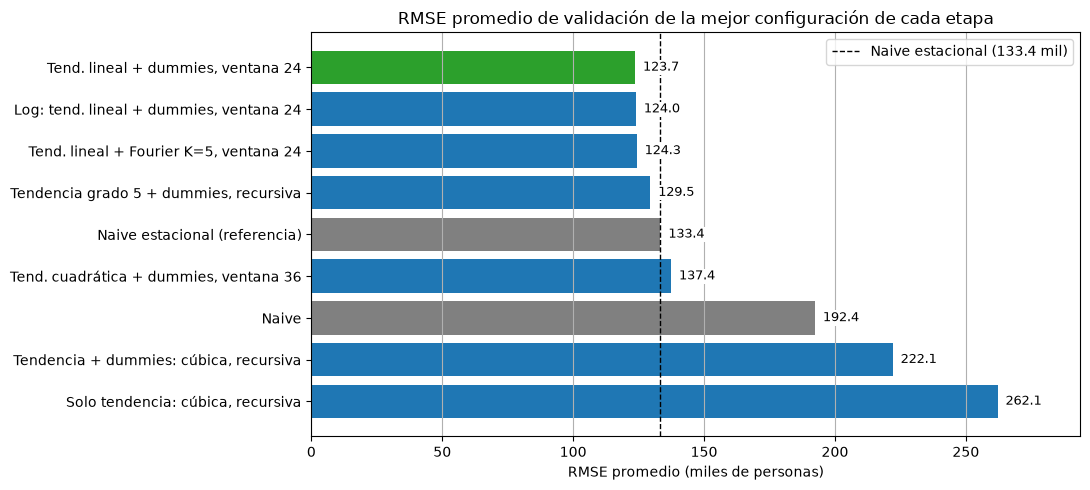

In [18]:
# Mejor configuración de cada etapa del análisis, junto con las referencias
mejores_por_etapa = {
    "Naive": "Naive",
    "Naive estacional (referencia)": "Naive estacional",
    "Solo tendencia: cúbica, recursiva": "Tend. cúbica",
    "Tendencia + dummies: cúbica, recursiva": "Tend. cúbica + dummies",
    "Tendencia grado 5 + dummies, recursiva": "Tend. grado 5 + dummies",
    "Tend. cuadrática + dummies, ventana 36": "Tend. cuadrática + dummies, ventana 36",
    "Tend. lineal + Fourier K=5, ventana 24": "Tend. lineal + Fourier K=5, ventana 24",
    "Log: tend. lineal + dummies, ventana 24": "Log: Tend. lineal + dummies, ventana 24",
    "Tend. lineal + dummies, ventana 24": "Tend. lineal + dummies, ventana 24",
}

resumen_seleccion = pd.DataFrame({
    "RMSE promedio": {etiqueta: validacion[nombre]["rmse"].mean() for etiqueta, nombre in mejores_por_etapa.items()},
    "MAPE promedio (%)": {etiqueta: validacion[nombre]["mape"].mean() for etiqueta, nombre in mejores_por_etapa.items()},
    "Cortes mejores que naive est.": {
        etiqueta: int((validacion[nombre]["rmse"] < validacion["Naive estacional"]["rmse"]).sum())
        for etiqueta, nombre in mejores_por_etapa.items()
    },
}).sort_values("RMSE promedio")
print(resumen_seleccion.round(2).to_string())

# Gráfica de barras del RMSE promedio, con la referencia del naive estacional
rmse_referencia = resumen_seleccion.loc["Naive estacional (referencia)", "RMSE promedio"]
orden = resumen_seleccion.sort_values("RMSE promedio", ascending=False)
colores = ["C2" if etiqueta == "Tend. lineal + dummies, ventana 24"
           else "gray" if etiqueta.startswith("Naive") else "C0" for etiqueta in orden.index]

fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(orden.index, orden["RMSE promedio"], color=colores)
ax.axvline(rmse_referencia, color="black", linestyle="--", linewidth=1,
           label=f"Naive estacional ({rmse_referencia:.1f} mil)")
for posicion, valor in enumerate(orden["RMSE promedio"]):
    # Fondo blanco para que la etiqueta se lea aunque cruce la línea de referencia
    ax.text(valor + 3, posicion, f"{valor:.1f}", va="center", fontsize=9,
            bbox=dict(facecolor="white", edgecolor="none", pad=1))
ax.set_xlim(0, orden["RMSE promedio"].max() * 1.12)
ax.set_title("RMSE promedio de validación de la mejor configuración de cada etapa")
ax.set_xlabel("RMSE promedio (miles de personas)")
ax.legend(loc="upper right")
ax.grid(axis="x")
plt.tight_layout()
plt.show()

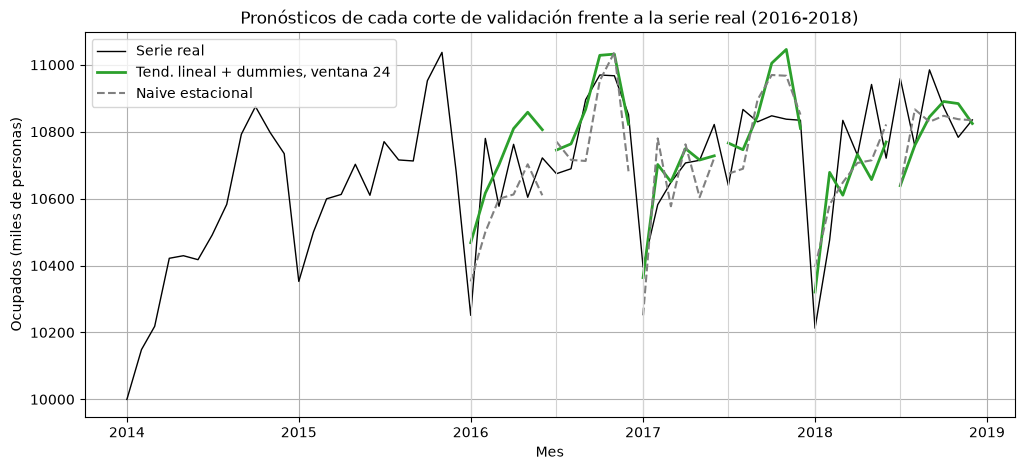

2016-01    194.9
2016-07     76.3
2017-01     41.4
2017-07     29.1
2018-01     -1.7
2018-07    -12.2


In [19]:
# Comportamiento del modelo con menor error en cada corte de validación
config_elegida = dict(tendencia="lineal", estacionalidad="dummies", ventana=24)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(train.loc["2014":], color="black", linewidth=1, label="Serie real")
for numero, (idx_ajuste, idx_validacion) in enumerate(tscv.split(train), start=1):
    serie_ajuste = train.iloc[idx_ajuste]
    fechas_validacion = train.index[idx_validacion]
    ax.plot(fechas_validacion, pronostico_regresion(serie_ajuste, len(idx_validacion), config_elegida),
            color="C2", linewidth=2, label="Tend. lineal + dummies, ventana 24" if numero == 1 else None)
    ax.plot(fechas_validacion, pronostico_naive_estacional(serie_ajuste, len(idx_validacion)),
            color="gray", linestyle="--", label="Naive estacional" if numero == 1 else None)
    ax.axvline(fechas_validacion[0], color="lightgray", linewidth=0.8)
ax.set_title("Pronósticos de cada corte de validación frente a la serie real (2016-2018)")
ax.set_xlabel("Mes")
ax.set_ylabel("Ocupados (miles de personas)")
ax.legend(loc="upper left")
ax.grid()
plt.show()

# Pendiente estimada en cada corte (coeficiente de t, en miles de personas por año)
pendientes_elegido = pd.Series({
    train.index[idx_validacion[0]].strftime("%Y-%m"):
        ajustar_regresion(train.iloc[idx_ajuste], config_elegida).params["t^1"]
    for idx_ajuste, idx_validacion in tscv.split(train)
}, name="Pendiente (miles por año)")
print(pendientes_elegido.round(1).to_string())

### Elección del modelo

| Modelo | RMSE promedio (miles) | MAPE promedio (%) | Cortes en que supera al naive estacional |
|---|---|---|---|
| **Tendencia lineal + dummies, ventana de 24 meses** | **123.68** | **0.94** | 3 |
| Logaritmo: tendencia lineal + dummies, ventana de 24 meses | 124.00 | 0.94 | 3 |
| Tendencia lineal + Fourier $K = 5$, ventana de 24 meses | 124.33 | 0.97 | 4 |
| Tendencia de grado 5 + dummies, ventana recursiva | 129.50 | 1.04 | 4 |
| Naive estacional | 133.36 | 1.05 | — |
| Tendencia cuadrática + dummies, ventana de 36 meses | 137.44 | 1.09 | 2 |

El modelo elegido es la regresión con **tendencia lineal y dummies de mes, estimada con los últimos 24 meses y en la escala original de la serie**:

$$y_t = \beta_0 + \beta_1 t + \sum_{j=2}^{12} \delta_j D_{j,t} + \varepsilon_t$$

Es el modelo con menor RMSE promedio, 7.3 % menor que el del naive estacional, y comparte el menor MAPE con su versión en escala logarítmica. Los dos modelos siguientes, en escala logarítmica y con términos de Fourier, tienen errores menos de 1 % mayores y la misma estructura: una tendencia lineal estimada con los últimos 24 meses. Esto indica que el aspecto decisivo del modelo es la ventana de estimación, y no la escala ni la forma de representar la estacionalidad. Entre ellos se elige la versión en escala original con dummies, que tiene el menor error y es la más fácil de interpretar, porque sus coeficientes están en miles de personas y cada uno corresponde al efecto de un mes. La tendencia de grado 5 tiene un error mayor y, como se vio en la sección 7, pronostica una caída de la serie que los datos no muestran.

La gráfica de los pronósticos por corte muestra que el modelo reproduce el patrón estacional y el nivel de la serie en la mayoría de los semestres. Sus mayores errores aparecen en el primer semestre de 2016, cuando la ventana de ajuste (2014 y 2015) todavía tenía crecimiento y el modelo extendió una pendiente de 194.9 mil personas por año sobre una serie que se había estancado, y en el máximo de octubre y noviembre de 2017, que sobreestima porque los efectos de esos meses se estimaron con 2015 y 2016, años en que el máximo fue más alto. Desde 2017, la pendiente estimada en cada corte está entre -12.2 y 41.4 mil personas por año, coherente con la tendencia casi plana de la serie.

Hay que tener en cuenta que se compararon cerca de 150 configuraciones con los mismos 6 cortes de validación, por lo que el error de validación del modelo elegido es probablemente algo optimista. La muestra de prueba, que no se ha usado en ninguna de estas decisiones, permite medir su desempeño con datos nuevos.

## 12. Evaluación de los supuestos de los residuales

Los intervalos de predicción de la regresión suponen que los errores del modelo no están autocorrelacionados, tienen varianza constante y siguen una distribución normal. Si los residuales del modelo elegido no cumplen estos supuestos, los pronósticos puntuales pueden seguir siendo útiles, pero los intervalos de predicción no tendrían la cobertura que indican. Se aplican las siguientes pruebas:

- **Autocorrelación:** prueba de rachas, que revisa si los signos de los residuales aparecen en un orden aleatorio, y pruebas de Box-Pierce y Ljung-Box, que revisan si las autocorrelaciones de los residuales son en conjunto distintas de cero.
- **Varianza constante:** prueba de Ljung-Box sobre los residuales al cuadrado, que detecta si la varianza depende de los errores anteriores (comportamiento ARCH o GARCH).
- **Normalidad:** pruebas de Jarque-Bera y Shapiro-Wilk, junto con el histograma y el gráfico Q-Q de los residuales.

En todas, la hipótesis nula corresponde al supuesto que se quiere verificar, y se rechaza con un p-valor menor a 0.05.

Los supuestos se evalúan sobre los residuales del modelo elegido ajustado con los últimos 24 meses del entrenamiento, de enero de 2017 a diciembre de 2018, que es el modelo que se evalúa en la muestra de prueba. Como el modelo estima 13 coeficientes con 24 observaciones, estas pruebas tienen poca potencia: con tan pocos residuales es difícil rechazar la hipótesis nula aunque el supuesto no se cumpla. Por eso, después se complementan con los errores de pronóstico a un mes del mismo modelo a lo largo de toda la serie.

                            OLS Regression Results                            
Dep. Variable:               Ocupados   R-squared:                       0.822
Model:                            OLS   Adj. R-squared:                  0.627
Method:                 Least Squares   F-statistic:                     4.225
Date:                Thu, 12 Nov 2026   Prob (F-statistic):             0.0117
Time:                        19:17:41   Log-Likelihood:                -137.71
No. Observations:                  24   AIC:                             301.4
Df Residuals:                      11   BIC:                             316.7
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       9773.8225    751.421     13.007      0.0

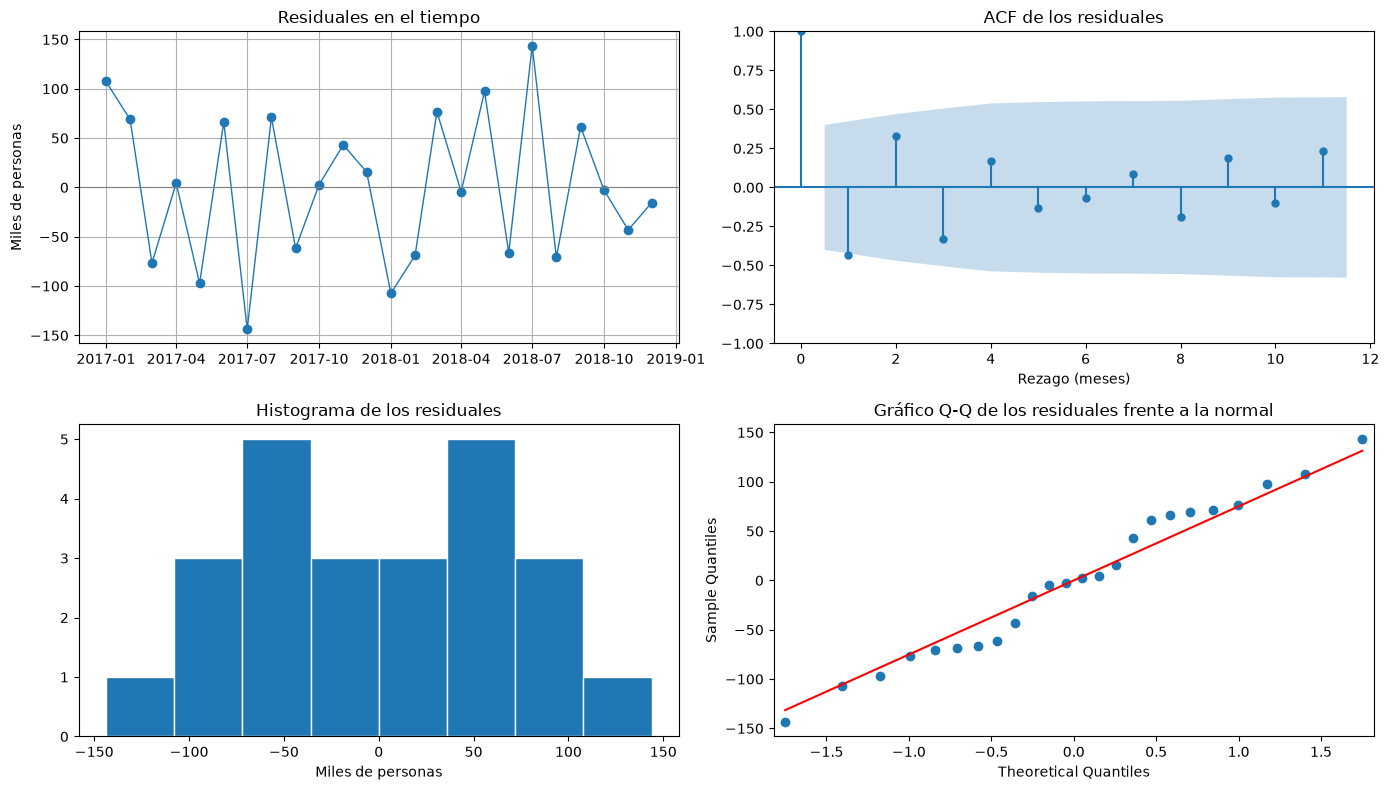

In [20]:
# Modelo elegido ajustado con los últimos 24 meses del entrenamiento (enero de 2017 a diciembre de 2018),
# que es el modelo que se evalúa en la muestra de prueba
ajuste_elegido = ajustar_regresion(train, config_elegida)
residuos = ajuste_elegido.resid
print(ajuste_elegido.summary())

# Gráficas de diagnóstico de los residuales
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

axes[0, 0].plot(residuos, marker="o", linewidth=1)
axes[0, 0].axhline(0, color="gray", linewidth=0.8)
axes[0, 0].set_title("Residuales en el tiempo")
axes[0, 0].set_ylabel("Miles de personas")
axes[0, 0].grid()

# Con 24 residuales se muestran hasta 11 rezagos (menos de la mitad de la muestra)
plot_acf(residuos, lags=11, ax=axes[0, 1], title="ACF de los residuales")
axes[0, 1].set_xlabel("Rezago (meses)")

axes[1, 0].hist(residuos, bins=8, edgecolor="white")
axes[1, 0].set_title("Histograma de los residuales")
axes[1, 0].set_xlabel("Miles de personas")

# line="s": recta ajustada a los cuantiles de los residuales, que no están estandarizados
sm.qqplot(residuos, line="s", ax=axes[1, 1])
axes[1, 1].set_title("Gráfico Q-Q de los residuales frente a la normal")

fig.tight_layout()
plt.show()

In [21]:
# Pruebas sobre los residuales del modelo elegido

# Prueba de rachas. H0: los signos de los residuales aparecen en orden aleatorio.
# cutoff=0 clasifica cada residual según su signo (por defecto se usaría la media, que con
# intercepto también es cero); correction=False, como en el notebook de clase.
estadistico_rachas, p_rachas = runstest_1samp(residuos, cutoff=0, correction=False)
print(f"Prueba de rachas: estadístico = {estadistico_rachas:.3f}, p-valor = {p_rachas:.3f}")

# Box-Pierce y Ljung-Box. H0: las autocorrelaciones hasta el rezago k son cero.
# Con 24 residuales se revisan hasta 6 rezagos (cerca de n/4).
rezagos = range(1, 7)
autocorrelacion = acorr_ljungbox(residuos, lags=rezagos, boxpierce=True, return_df=True)
print("\nBox-Pierce y Ljung-Box sobre los residuales:")
print(autocorrelacion.round(3).to_string())

# Ljung-Box sobre los residuales al cuadrado. H0: no hay autocorrelación en los cuadrados,
# es decir, no hay comportamiento ARCH o GARCH. Los residuales ya tienen media cero.
heteroscedasticidad = acorr_ljungbox(residuos ** 2, lags=rezagos, return_df=True)
print("\nLjung-Box sobre los residuales al cuadrado:")
print(heteroscedasticidad.round(3).to_string())

# Normalidad. H0: los residuales provienen de una distribución normal.
jarque_bera = stats.jarque_bera(residuos)
shapiro_wilk = stats.shapiro(residuos)
print(f"\nJarque-Bera: estadístico = {jarque_bera.statistic:.3f}, p-valor = {jarque_bera.pvalue:.3f}")
print(f"Shapiro-Wilk: estadístico = {shapiro_wilk.statistic:.3f}, p-valor = {shapiro_wilk.pvalue:.3f}")

Prueba de rachas: estadístico = 2.087, p-valor = 0.037

Box-Pierce y Ljung-Box sobre los residuales:
   lb_stat  lb_pvalue  bp_stat  bp_pvalue
1    5.138      0.023    4.546      0.033
2    8.164      0.017    7.105      0.029
3   11.379      0.010    9.702      0.021
4   12.260      0.016   10.380      0.034
5   12.846      0.025   10.809      0.055
6   12.999      0.043   10.914      0.091

Ljung-Box sobre los residuales al cuadrado:
   lb_stat  lb_pvalue
1    0.098      0.754
2    1.207      0.547
3    9.845      0.020
4    9.871      0.043
5   12.500      0.029
6   19.054      0.004

Jarque-Bera: estadístico = 0.964, p-valor = 0.618
Shapiro-Wilk: estadístico = 0.970, p-valor = 0.664


### Resultados de los supuestos con los residuales de la ventana

| Prueba | Hipótesis nula | p-valor | Resultado |
|---|---|---|---|
| Rachas | Signos en orden aleatorio | 0.037 | Se rechaza |
| Ljung-Box, rezago 1 | Sin autocorrelación | 0.023 | Se rechaza |
| Ljung-Box, rezagos 1 a 6 | Sin autocorrelación | 0.010 a 0.043 | Se rechaza |
| Ljung-Box sobre los cuadrados, rezagos 3 a 6 | Sin comportamiento ARCH | 0.004 a 0.043 | Se rechaza |
| Jarque-Bera | Normalidad | 0.618 | No se rechaza |
| Shapiro-Wilk | Normalidad | 0.664 | No se rechaza |

Estos resultados no pueden interpretarse directamente, por una propiedad del modelo con ventana de 24 meses. En la regresión por MCO, los residuales son ortogonales a cada regresor, y como hay una dummy por mes (y la constante para enero), la suma de los residuales de cada mes es cero. Con 24 meses, cada mes tiene solo dos observaciones, de modo que el residual de 2018 es aproximadamente el negativo del de 2017: por ejemplo, 108.0 en enero de 2017 y -107.0 en enero de 2018, y -143.0 en julio de 2017 y 143.0 en julio de 2018. En la gráfica de los residuales en el tiempo, el segundo año repite el primero con el signo invertido.

Esta restricción afecta todas las pruebas. Los 24 residuales tienen en realidad cerca de 11 valores libres, igual que los grados de libertad del modelo. Su distribución es simétrica por construcción, por lo que la asimetría es exactamente 0 y las pruebas de normalidad no la rechazan sin que esto indique que los errores sean normales. Los cuadrados del segundo año repiten los del primero, lo que genera la autocorrelación detectada en los residuales al cuadrado. Y la autocorrelación negativa del rezago 1 ($r_1 \approx -0.43$, con un estadístico de Durbin-Watson de 2.78) no se puede separar del efecto de la restricción. Esto no afecta la evaluación del pronóstico, que se hizo con errores fuera de la muestra de ajuste, pero sí impide usar los residuales de la ventana para verificar los supuestos.

El `summary` también muestra que la pendiente estimada con 2017 y 2018 es de 32.1 mil personas por año, no significativa (p-valor de 0.493), coherente con una serie que no creció en esos años, y que el $R^2$ ajustado es de 0.627, bastante menor que el $R^2$ de 0.822, porque el modelo estima 13 coeficientes con 24 observaciones.

Para evaluar los supuestos sin esta restricción, se usan los errores de pronóstico a un mes del mismo modelo: para cada mes desde enero de 2003 hasta diciembre de 2018, el modelo se ajusta con los 24 meses anteriores y se pronostica el mes siguiente. Así se obtienen 192 errores, cada uno calculado con datos que el modelo no usó para estimar sus coeficientes. Además, con estos pronósticos se puede medir qué porcentaje de los valores reales cae dentro del intervalo de predicción del 95 % del modelo, que es la consecuencia práctica de que los supuestos se cumplan o no.

Errores de pronóstico a un mes: 192 meses, de 2003-01 a 2018-12
Media del error: -3.9 mil | Desviación estándar: 176.0 mil
Cobertura del intervalo de predicción del 95 %: 90.1 %


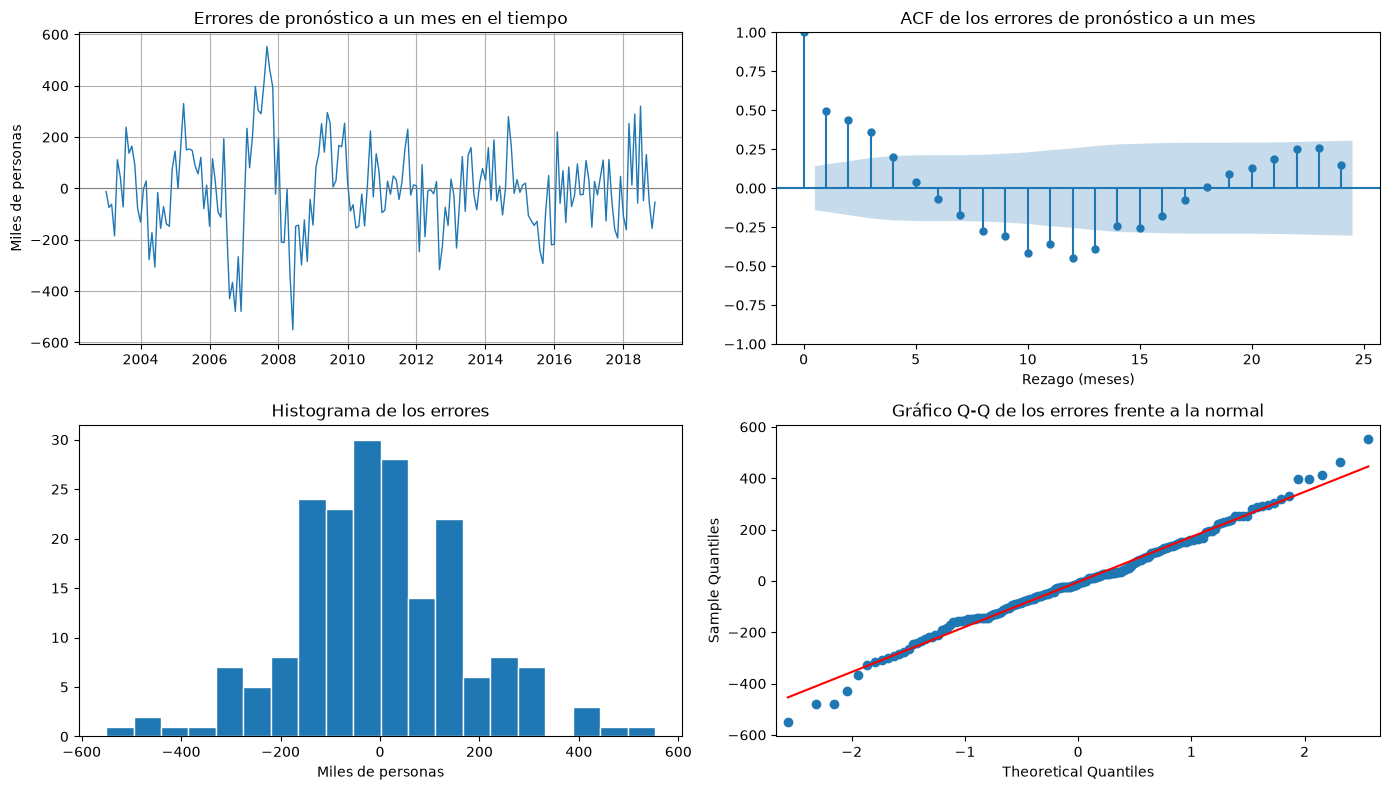


Prueba de rachas: estadístico = -1.980, p-valor = 0.048

Box-Pierce y Ljung-Box sobre los errores:
    lb_stat  lb_pvalue  bp_stat  bp_pvalue
1    48.093        0.0   47.350        0.0
2    85.839        0.0   84.317        0.0
3   111.450        0.0  109.268        0.0
6   120.688        0.0  118.209        0.0
12  265.566        0.0  253.906        0.0
18  330.188        0.0  313.203        0.0
24  376.410        0.0  353.684        0.0

Ljung-Box sobre los errores al cuadrado (sin media):
    lb_stat  lb_pvalue
1    37.125        0.0
2    66.564        0.0
3    75.111        0.0
6    92.991        0.0
12  191.638        0.0
18  215.136        0.0
24  220.360        0.0

Prueba ARCH-LM de Engle (12 rezagos): estadístico = 59.976, p-valor = 0.000

Jarque-Bera: estadístico = 3.922, p-valor = 0.141
Shapiro-Wilk: estadístico = 0.991, p-valor = 0.276


In [22]:
# Errores de pronóstico a un mes del modelo elegido: para cada mes desde enero de 2003,
# el modelo se ajusta con los 24 meses anteriores y pronostica el mes siguiente.
# También se registra si el valor real cae dentro del intervalo de predicción del 95 %.
filas = []
for posicion in range(24, len(train)):
    serie_ajuste = train.iloc[:posicion]
    ajuste = ajustar_regresion(serie_ajuste, config_elegida)   # usa solo los últimos 24 meses
    X_siguiente = construir_regresores(fechas_siguientes(serie_ajuste, 1), config_elegida["tendencia"],
                                       config_elegida["estacionalidad"])
    prediccion = ajuste.get_prediction(X_siguiente).summary_frame(alpha=0.05)
    valor_real = train.iloc[posicion]
    filas.append({
        "mes": train.index[posicion],
        "error": valor_real - prediccion["mean"].iloc[0],
        "dentro_intervalo": prediccion["obs_ci_lower"].iloc[0] <= valor_real <= prediccion["obs_ci_upper"].iloc[0],
    })
errores_un_mes = pd.DataFrame(filas).set_index("mes")
error = errores_un_mes["error"]
print(f"Errores de pronóstico a un mes: {len(error)} meses, de {error.index[0]:%Y-%m} a {error.index[-1]:%Y-%m}")
print(f"Media del error: {error.mean():.1f} mil | Desviación estándar: {error.std():.1f} mil")
print(f"Cobertura del intervalo de predicción del 95 %: {100 * errores_un_mes['dentro_intervalo'].mean():.1f} %")

# Gráficas de diagnóstico de los errores
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

axes[0, 0].plot(error, linewidth=1)
axes[0, 0].axhline(0, color="gray", linewidth=0.8)
axes[0, 0].set_title("Errores de pronóstico a un mes en el tiempo")
axes[0, 0].set_ylabel("Miles de personas")
axes[0, 0].grid()

plot_acf(error, lags=24, ax=axes[0, 1], title="ACF de los errores de pronóstico a un mes")
axes[0, 1].set_xlabel("Rezago (meses)")

axes[1, 0].hist(error, bins=20, edgecolor="white")
axes[1, 0].set_title("Histograma de los errores")
axes[1, 0].set_xlabel("Miles de personas")

sm.qqplot(error, line="s", ax=axes[1, 1])
axes[1, 1].set_title("Gráfico Q-Q de los errores frente a la normal")

fig.tight_layout()
plt.show()

# Pruebas sobre los errores de pronóstico a un mes
estadistico_rachas, p_rachas = runstest_1samp(error, cutoff=0, correction=False)
print(f"\nPrueba de rachas: estadístico = {estadistico_rachas:.3f}, p-valor = {p_rachas:.3f}")

rezagos_revisados = [1, 2, 3, 6, 12, 18, 24]
autocorrelacion = acorr_ljungbox(error, lags=rezagos_revisados, boxpierce=True, return_df=True)
print("\nBox-Pierce y Ljung-Box sobre los errores:")
print(autocorrelacion.round(3).to_string())

# Los errores se centran antes de elevarlos al cuadrado, porque su media no es exactamente cero
heteroscedasticidad = acorr_ljungbox((error - error.mean()) ** 2, lags=rezagos_revisados, return_df=True)
print("\nLjung-Box sobre los errores al cuadrado (sin media):")
print(heteroscedasticidad.round(3).to_string())

# result_object=True devuelve un resultado con nombres (lm, lmpval, fval, fpval),
# que es el comportamiento por defecto en las versiones siguientes de statsmodels
prueba_arch = het_arch(error - error.mean(), nlags=12, result_object=True)
print(f"\nPrueba ARCH-LM de Engle (12 rezagos): estadístico = {prueba_arch.lm:.3f}, p-valor = {prueba_arch.lmpval:.3f}")

jarque_bera = stats.jarque_bera(error)
shapiro_wilk = stats.shapiro(error)
print(f"\nJarque-Bera: estadístico = {jarque_bera.statistic:.3f}, p-valor = {jarque_bera.pvalue:.3f}")
print(f"Shapiro-Wilk: estadístico = {shapiro_wilk.statistic:.3f}, p-valor = {shapiro_wilk.pvalue:.3f}")

### Resultados de los supuestos con los errores de pronóstico a un mes

| Prueba | Hipótesis nula | p-valor | Resultado |
|---|---|---|---|
| Rachas | Signos en orden aleatorio | 0.048 | Se rechaza |
| Ljung-Box, rezagos 1 a 24 | Sin autocorrelación | < 0.001 | Se rechaza |
| Ljung-Box sobre los errores al cuadrado, rezagos 1 a 24 | Sin comportamiento ARCH | < 0.001 | Se rechaza |
| ARCH-LM de Engle, 12 rezagos | Sin comportamiento ARCH | < 0.001 | Se rechaza |
| Jarque-Bera | Normalidad | 0.141 | No se rechaza |
| Shapiro-Wilk | Normalidad | 0.276 | No se rechaza |

Los 192 errores de pronóstico a un mes tienen una media de -3.9 mil personas, cercana a cero frente a su desviación estándar de 176.0 mil, de modo que el modelo no sobreestima ni subestima la serie de forma sistemática. Sin embargo, los errores no se comportan como ruido blanco.

**Autocorrelación.** La ACF muestra dos patrones. En los rezagos 1 a 3, la autocorrelación es positiva (cerca de 0.50, 0.44 y 0.36): cuando la serie cambia de nivel, el modelo tarda en ajustarse, porque cada mes nuevo pesa solo una de 24 observaciones en la estimación, y los errores de meses consecutivos tienden a tener el mismo signo. La prueba de rachas es coherente con esto, porque encuentra menos cambios de signo de los esperados. Alrededor del rezago 12, la autocorrelación es negativa (cerca de -0.45): como el efecto de cada mes se estima con los dos años anteriores, un mes atípico en un año desplaza el efecto estimado de ese mes, y el error del mismo mes del año siguiente tiende a tener el signo contrario.

**Varianza.** Los errores más grandes, de hasta 550 mil personas en valor absoluto, se concentran entre 2006 y 2008, el periodo de la pausa y la posterior recuperación de la tendencia descrito en la sección 4, y son menores en los demás años. Este agrupamiento de errores grandes es lo que detectan la prueba de Ljung-Box sobre los errores al cuadrado y la prueba ARCH-LM.

**Normalidad.** Las pruebas no rechazan la normalidad, y el gráfico Q-Q sigue la recta salvo en los valores más extremos, que también corresponden a 2006-2008.

Por lo tanto, el modelo elegido no cumple los supuestos de independencia y varianza constante de los errores. Ninguna de las alternativas evaluadas en las secciones anteriores corrige estas fallas: la escala logarítmica estabiliza una varianza que crece con el nivel de la serie, mientras que aquí la varianza alta se concentra en un periodo; una ventana más larga reduce la autocorrelación del rezago 12, pero aumenta la de corto plazo, porque el modelo se ajusta más lento a los cambios de nivel; y la estacionalidad ya está representada por completo con las dummies. La autocorrelación de corto plazo indica que la serie tiene una dinámica que una regresión sobre el tiempo no captura, y que requeriría incluir en el modelo la relación de cada error con los anteriores.

Esto tiene dos consecuencias. Primero, los errores estándar y los p-valores del `summary` no son confiables. Segundo, los intervalos de predicción calculados con MCO son demasiado estrechos: en los pronósticos a un mes, el intervalo del 95 % contuvo el valor real solo en el 90.1 % de los meses, y en un horizonte de 6 meses la cobertura probablemente es menor, porque la autocorrelación positiva hace que los errores se acumulen en la misma dirección. El pronóstico puntual, en cambio, sigue siendo válido, porque los errores no tienen sesgo y su desempeño se midió directamente fuera de la muestra en la validación. Por eso, en el pronóstico final, el intervalo de MCO se complementa con un intervalo construido con los errores de pronóstico observados del modelo.

## 13. Evaluación en la muestra de prueba y comparación con el ejercicio anterior

El modelo elegido se ajusta con los últimos 24 meses del entrenamiento (enero de 2017 a diciembre de 2018) y pronostica los 6 meses de prueba, de enero a junio de 2019, que no se usaron en ninguna decisión anterior. Se compara con las referencias naive y con el modelo elegido en el ejercicio de promedios móviles y suavización exponencial, el Holt-Winters aditivo sin tendencia (ETS ANA), para saber si la regresión mejora el mejor pronóstico obtenido con esos métodos. La comparación se hace con la misma evidencia con la que se eligió cada modelo: primero en los 6 cortes de validación y luego en la prueba. El modelo ETS ANA se vuelve a calcular en este notebook y se verifica que sus resultados coincidan con los reportados en ese ejercicio.

Validación (6 cortes, 2016-2018):
                                    RMSE promedio  MAPE promedio (%)
Tend. lineal + dummies, ventana 24         123.68               0.94
Holt-Winters ANA                           122.02               0.98
Naive estacional                           133.36               1.05

RMSE por corte (miles):
                   Tend. lineal + dummies, ventana 24  Holt-Winters ANA  Naive estacional
inicio_validacion                                                                        
2016-01                                         164.9             152.8             149.4
2016-07                                          57.5              67.8             113.5
2017-01                                          65.9             105.8             122.8
2017-07                                         128.9             127.6             107.3
2018-01                                         176.0             150.1             153.3
2018-07                            

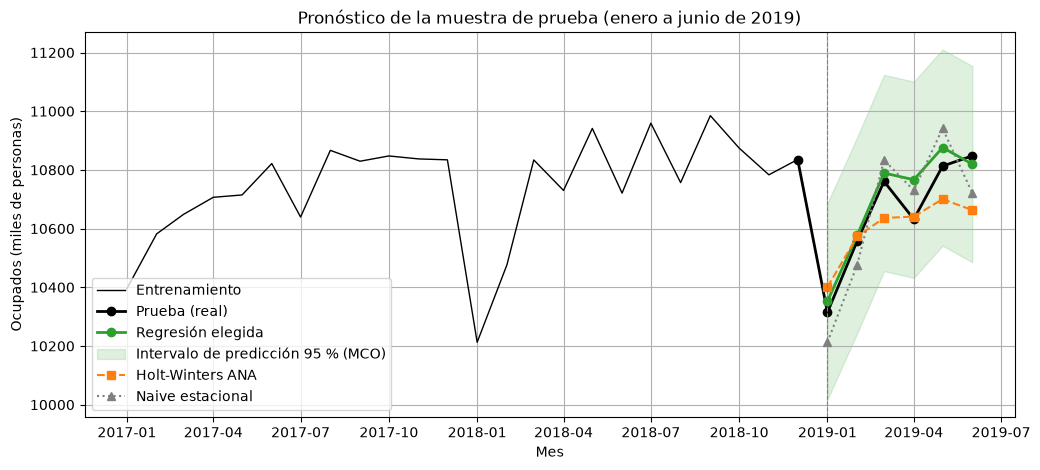

In [23]:
def pronostico_holt_winters_ana(serie_ajuste, h):
    """Holt-Winters con error y estacionalidad aditivos y sin tendencia (ETS ANA).

    Es el modelo elegido en el ejercicio de suavización exponencial; los parámetros
    se estiman por máxima verosimilitud solo con serie_ajuste.
    """
    modelo = ETSModel(serie_ajuste, error="add", trend=None, damped_trend=False,
                      seasonal="add", seasonal_periods=12)
    return np.asarray(modelo.fit(disp=False).forecast(h))


nombre_elegido = "Tend. lineal + dummies, ventana 24"
validacion["Holt-Winters ANA"] = evaluar_validacion(pronostico_holt_winters_ana)

# Comparación en los 6 cortes de validación
modelos_finales = [nombre_elegido, "Holt-Winters ANA", "Naive estacional"]
comparacion_validacion = pd.DataFrame({
    "RMSE promedio": {nombre: validacion[nombre]["rmse"].mean() for nombre in modelos_finales},
    "MAPE promedio (%)": {nombre: validacion[nombre]["mape"].mean() for nombre in modelos_finales},
})
print("Validación (6 cortes, 2016-2018):")
print(comparacion_validacion.round(2).to_string())
print("\nRMSE por corte (miles):")
print(pd.DataFrame({nombre: validacion[nombre]["rmse"] for nombre in modelos_finales}).round(1).to_string())
cortes_regresion_mejor = int((validacion[nombre_elegido]["rmse"] < validacion["Holt-Winters ANA"]["rmse"]).sum())
print(f"\nCortes (de 6) en que la regresión supera al Holt-Winters ANA: {cortes_regresion_mejor}")

# Pronósticos de la muestra de prueba: cada modelo se ajusta con el entrenamiento completo
# (la regresión usa solo sus últimos 24 meses) y pronostica enero a junio de 2019
funciones_prueba = {
    nombre_elegido: lambda serie_ajuste, h: pronostico_regresion(serie_ajuste, h, config_elegida),
    "Holt-Winters ANA": pronostico_holt_winters_ana,
    "Naive estacional": pronostico_naive_estacional,
    "Naive": pronostico_naive,
}
pronosticos_prueba = pd.DataFrame(
    {nombre: funcion(train, horizonte) for nombre, funcion in funciones_prueba.items()}, index=test.index
)
metricas_prueba = pd.DataFrame({
    "RMSE (miles)": {nombre: np.sqrt(mean_squared_error(test, pronosticos_prueba[nombre])) for nombre in pronosticos_prueba},
    "MAPE (%)": {nombre: 100 * mean_absolute_percentage_error(test, pronosticos_prueba[nombre]) for nombre in pronosticos_prueba},
})
print("\nPrueba (enero a junio de 2019):")
print(metricas_prueba.round(2).to_string())

# Verificación frente a los resultados reportados en el ejercicio de suavización exponencial.
# El modelo ETS se estima con un optimizador numérico, cuyo resultado puede variar levemente
# entre sistemas operativos o procesadores, por eso la comparación usa una tolerancia de 3 %.
RMSE_VALIDACION_ANA, MAPE_VALIDACION_ANA = 122.02, 0.98
RMSE_PRUEBA_ANA, MAPE_PRUEBA_ANA = 108.16, 0.83
assert np.isclose(comparacion_validacion.loc["Holt-Winters ANA", "RMSE promedio"], RMSE_VALIDACION_ANA, rtol=0.03)
assert np.isclose(comparacion_validacion.loc["Holt-Winters ANA", "MAPE promedio (%)"], MAPE_VALIDACION_ANA, rtol=0.03)
assert np.isclose(metricas_prueba.loc["Holt-Winters ANA", "RMSE (miles)"], RMSE_PRUEBA_ANA, rtol=0.03)
assert np.isclose(metricas_prueba.loc["Holt-Winters ANA", "MAPE (%)"], MAPE_PRUEBA_ANA, rtol=0.03)
print("\nVerificación: los resultados del Holt-Winters ANA coinciden con los del ejercicio anterior.")

# Intervalo de predicción del 95 % de la regresión en la prueba (calculado con MCO)
X_prueba = construir_regresores(test.index, config_elegida["tendencia"], config_elegida["estacionalidad"])
intervalo_prueba = ajuste_elegido.get_prediction(X_prueba).summary_frame(alpha=0.05)
tabla_prueba = pd.DataFrame({
    "Real": test,
    "Regresión": pronosticos_prueba[nombre_elegido],
    "Límite inferior 95 %": intervalo_prueba["obs_ci_lower"].values,
    "Límite superior 95 %": intervalo_prueba["obs_ci_upper"].values,
    "Holt-Winters ANA": pronosticos_prueba["Holt-Winters ANA"],
    "Naive estacional": pronosticos_prueba["Naive estacional"],
})
tabla_prueba["Error regresión"] = tabla_prueba["Real"] - tabla_prueba["Regresión"]
tabla_prueba["Dentro del intervalo"] = tabla_prueba["Real"].between(
    tabla_prueba["Límite inferior 95 %"], tabla_prueba["Límite superior 95 %"]
)
print("\nPronósticos de la prueba (miles de personas):")
print(tabla_prueba.round(1).to_string())

# Gráfica de los pronósticos de la prueba. La línea real se dibuja desde el último mes
# de entrenamiento solo para que la gráfica se vea continua; los datos no cambian.
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(train.loc["2017":], color="black", linewidth=1, label="Entrenamiento")
ax.plot(pd.concat([train.iloc[-1:], test]), color="black", linewidth=2, marker="o", label="Prueba (real)")
ax.plot(pronosticos_prueba[nombre_elegido], color="C2", linewidth=2, marker="o", label="Regresión elegida")
ax.fill_between(test.index, tabla_prueba["Límite inferior 95 %"], tabla_prueba["Límite superior 95 %"],
                color="C2", alpha=0.15, label="Intervalo de predicción 95 % (MCO)")
ax.plot(pronosticos_prueba["Holt-Winters ANA"], color="C1", linestyle="--", marker="s", label="Holt-Winters ANA")
ax.plot(pronosticos_prueba["Naive estacional"], color="gray", linestyle=":", marker="^", label="Naive estacional")
ax.axvline(test.index[0], color="gray", linestyle="--", linewidth=0.8)
ax.set_title("Pronóstico de la muestra de prueba (enero a junio de 2019)")
ax.set_xlabel("Mes")
ax.set_ylabel("Ocupados (miles de personas)")
ax.legend(loc="lower left")
ax.grid()
plt.show()

### Resultados de la evaluación en la muestra de prueba

Los resultados del Holt-Winters ANA calculados en este notebook coinciden con los reportados en el ejercicio de suavización exponencial, de modo que la comparación se hace contra el mismo modelo.

| Modelo | RMSE validación (miles) | MAPE validación (%) | RMSE prueba (miles) | MAPE prueba (%) |
|---|---|---|---|---|
| **Tend. lineal + dummies, ventana 24** | 123.68 | **0.94** | **65.20** | **0.49** |
| Holt-Winters ANA | **122.02** | 0.98 | 108.16 | 0.83 |
| Naive estacional | 133.36 | 1.05 | 103.75 | 0.95 |
| Naive | 192.42 | 1.41 | 256.90 | 1.77 |

**Validación.** La regresión y el Holt-Winters ANA tienen un desempeño prácticamente igual. El ANA tiene un RMSE promedio 1.66 mil personas menor (cerca de 1.4 %) y es mejor en 4 de los 6 cortes, mientras que la regresión tiene un MAPE promedio menor. Los dos cortes en que la regresión es mejor, julio de 2016 y enero de 2017, son también aquellos en que obtiene sus errores más bajos (57.5 y 65.9 mil).

**Prueba.** La regresión reduce el RMSE del Holt-Winters ANA de 108.16 a 65.20 mil personas, cerca de 40 %, y también supera a las dos referencias naive. Sus errores mensuales son pequeños y de signo casi siempre negativo: el modelo sobreestima levemente cinco de los seis meses, entre 19 y 63 mil personas, con la excepción de abril, cuando el número de ocupados bajó frente a marzo y el error fue de 134.5 mil. El Holt-Winters ANA, en cambio, subestima marzo, mayo y junio, porque al no tener tendencia pronostica entre 10 636 y 10 701 mil personas en esos meses, mientras que la serie subió hasta cerca de 10 850 mil. La regresión, al estimarse solo con los dos últimos años, parte del nivel reciente de la serie y lo proyecta con una pendiente pequeña. Los seis valores reales quedan dentro del intervalo de predicción del 95 % de la regresión.

La diferencia en la prueba debe interpretarse con cautela. La prueba es un solo periodo de 6 meses, y el RMSE de 65.20 mil está cerca del extremo inferior del rango que la regresión obtuvo en los cortes de validación (57.5 a 176.0 mil), lo que indica que fue un periodo favorable para el modelo. Con la evidencia de la validación y de la prueba, la regresión con tendencia lineal, dummies mensuales y ventana de 24 meses es al menos tan buena como el mejor modelo de suavización exponencial y mejor que las referencias naive, por lo que se usa para el pronóstico final.

## 14. Pronóstico de los próximos 6 meses

Para pronosticar julio a diciembre de 2019, el modelo elegido se ajusta con los últimos 24 meses de la serie completa, de julio de 2017 a junio de 2019, de modo que el pronóstico parta de la información más reciente, incluidos los meses de prueba. Es la misma regla con la que el modelo se validó y se evaluó en la prueba.

Como los errores del modelo están autocorrelacionados y no tienen varianza constante (sección 12), el intervalo de predicción calculado con MCO puede no tener la cobertura nominal del 95 %, sobre todo en los meses más lejanos del horizonte. Por eso se calcula también un **intervalo empírico** a partir de los errores que el modelo ha cometido en la historia de la serie: desde cada mes de origen, a partir del mes 24, el modelo se ajusta con los 24 meses anteriores y pronostica los 6 meses siguientes. Esto da, para cada horizonte $h = 1, \dots, 6$, una muestra de errores de pronóstico reales. Sus percentiles 2.5 y 97.5, sumados al pronóstico puntual, forman el intervalo empírico del 95 % para ese horizonte. Con los mismos ajustes se mide la cobertura real del intervalo de MCO en cada horizonte.

Periodo de ajuste: 2017-07 a 2019-06
Pendiente de la tendencia: 29.2 mil personas por año

Errores históricos por horizonte (orígenes de 2002-12 a 2018-12, miles de personas):
   errores  media  desviacion  cobertura_mco  percentil_2_5  percentil_97_5
h                                                                          
1      193   -4.1       175.5           90.2         -334.8           343.6
2      193   -5.7       186.6           89.6         -371.0           344.2
3      193   -7.1       193.9           88.6         -414.1           355.8
4      193   -9.2       202.1           87.6         -421.2           367.3
5      193  -10.2       207.7           85.0         -430.3           361.8
6      193  -12.2       211.4           83.9         -430.4           360.0

Pronóstico de julio a diciembre de 2019 (miles de personas):
            Pronóstico  MCO inferior  MCO superior  Empírico inferior  Empírico superior
mes                                                              

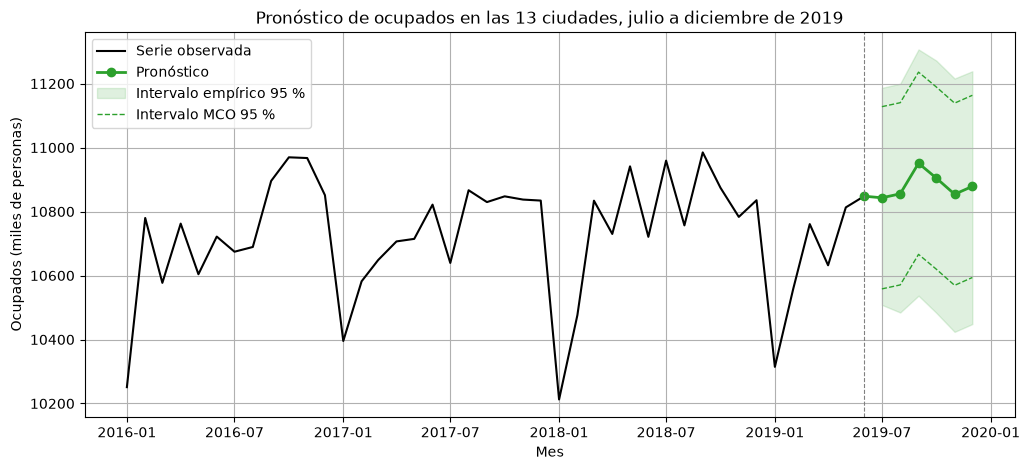

In [24]:
# Ajuste final: ajustar_regresion toma los últimos 24 meses de la serie completa
# (julio de 2017 a junio de 2019), la misma regla usada en la validación y en la prueba
ajuste_final = ajustar_regresion(ocupados, config_elegida)
print("Periodo de ajuste:", ajuste_final.model.data.row_labels[0].strftime("%Y-%m"), "a",
      ajuste_final.model.data.row_labels[-1].strftime("%Y-%m"))
print(f"Pendiente de la tendencia: {ajuste_final.params['t^1']:.1f} mil personas por año")

fechas_pronostico = fechas_siguientes(ocupados, horizonte)
X_pronostico = construir_regresores(fechas_pronostico, config_elegida["tendencia"], config_elegida["estacionalidad"])
prediccion_final = ajuste_final.get_prediction(X_pronostico).summary_frame(alpha=0.05)

# Errores históricos por horizonte: desde cada mes de origen, el modelo se ajusta con los
# 24 meses anteriores y pronostica los 6 siguientes. Se usa toda la serie, incluidos los meses
# de prueba, porque la evaluación del modelo ya terminó y aquí solo se mide su incertidumbre.
filas = []
for origen in range(24, len(ocupados) - horizonte + 1):
    serie_ajuste = ocupados.iloc[:origen]
    ajuste = ajustar_regresion(serie_ajuste, config_elegida)
    X_siguientes = construir_regresores(fechas_siguientes(serie_ajuste, horizonte),
                                        config_elegida["tendencia"], config_elegida["estacionalidad"])
    prediccion = ajuste.get_prediction(X_siguientes).summary_frame(alpha=0.05)
    reales = ocupados.iloc[origen:origen + horizonte].values
    for paso in range(horizonte):
        filas.append({
            "origen": serie_ajuste.index[-1],
            "h": paso + 1,
            "error": reales[paso] - prediccion["mean"].iloc[paso],
            "dentro_intervalo_mco": prediccion["obs_ci_lower"].iloc[paso] <= reales[paso] <= prediccion["obs_ci_upper"].iloc[paso],
        })
errores_horizonte = pd.DataFrame(filas)

resumen_horizonte = errores_horizonte.groupby("h").agg(
    errores=("error", "size"),
    media=("error", "mean"),
    desviacion=("error", "std"),
    cobertura_mco=("dentro_intervalo_mco", lambda dentro: 100 * dentro.mean()),
    percentil_2_5=("error", lambda error: error.quantile(0.025)),
    percentil_97_5=("error", lambda error: error.quantile(0.975)),
)
print(f"\nErrores históricos por horizonte (orígenes de {errores_horizonte['origen'].min():%Y-%m} "
      f"a {errores_horizonte['origen'].max():%Y-%m}, miles de personas):")
print(resumen_horizonte.round(1).to_string())

# Tabla del pronóstico con los dos intervalos del 95 %
tabla_pronostico = pd.DataFrame({
    "Pronóstico": prediccion_final["mean"].values,
    "MCO inferior": prediccion_final["obs_ci_lower"].values,
    "MCO superior": prediccion_final["obs_ci_upper"].values,
    "Empírico inferior": prediccion_final["mean"].values + resumen_horizonte["percentil_2_5"].values,
    "Empírico superior": prediccion_final["mean"].values + resumen_horizonte["percentil_97_5"].values,
}, index=fechas_pronostico)
tabla_pronostico.index.name = "mes"
print("\nPronóstico de julio a diciembre de 2019 (miles de personas):")
print(tabla_pronostico.round(1).to_string())

# Gráfica del pronóstico final con los dos intervalos
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(ocupados.loc["2016":], color="black", linewidth=1.5, label="Serie observada")
ax.plot(pd.concat([ocupados.iloc[-1:], tabla_pronostico["Pronóstico"]]), color="C2", linewidth=2,
        marker="o", label="Pronóstico")
ax.fill_between(tabla_pronostico.index, tabla_pronostico["Empírico inferior"], tabla_pronostico["Empírico superior"],
                color="C2", alpha=0.15, label="Intervalo empírico 95 %")
ax.plot(tabla_pronostico["MCO inferior"], color="C2", linestyle="--", linewidth=1, label="Intervalo MCO 95 %")
ax.plot(tabla_pronostico["MCO superior"], color="C2", linestyle="--", linewidth=1)
ax.axvline(ocupados.index[-1], color="gray", linestyle="--", linewidth=0.8)
ax.set_title("Pronóstico de ocupados en las 13 ciudades, julio a diciembre de 2019")
ax.set_xlabel("Mes")
ax.set_ylabel("Ocupados (miles de personas)")
ax.legend(loc="upper left")
ax.grid()
plt.show()